<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_MembershipUnlearning_Su2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN membership inference and Quantum Machine Unlearning: Su et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Junjian Su, Runze He, Guanghui Li, Sujuan Qin, Zhimin He, Haozhen Situ and Fei Gao,
> "From Membership-Privacy Leakage to Quantum Machine Unlearning",
> Physical Review Applied 25, 044056 (2026); arXiv:2509.06086v3. https://doi.org/10.1103/PhysRevApplied.25.044056
> Authors' code: https://github.com/Sujun124/QMU (pinned here at commit `e557accf9aab4f7bebe86c852d554971adde6e6d`).

**The story in five sentences.** A model can betray whether a particular picture was in its training set (a *membership inference attack*, MIA).
The paper asks two questions: do quantum neural networks (QNNs) leak membership this way, and can *machine unlearning* make a trained QNN forget
a whole class of digits without retraining from scratch? It attacks two QNNs on MNIST (a "basic" QNN fed by PCA and a hybrid CNN+QNN, "HQNN"),
with an attacker who can only query the model like a cloud API. It then repairs the models with three unlearning methods (gradient ascent GA,
Selective Synaptic Dampening SSD, and a hybrid called Relative Gradient Ascent RGA) and measures how the number of measurement shots helps or
hurts both the attacker and the unlearner. The notebook redraws the paper's Table I, Table II and Figs. 3, 5, 6, 7 on a CPU simulator.

**What the notebook does.**
1. Downloads MNIST (public), draws 1,000 random images, splits 600 train / 400 test and picks the class to forget from {4, 5, 8}.
2. Builds the paper's two models with a fast exact PyTorch simulator of the 8-qubit circuit and **proves** (to 1e-9) that it equals the authors' own PennyLane circuit, which is cloned at the pinned commit; the executed circuits are drawn with `qml.draw_mpl`.
3. Trains the original model A_o (all of D_train) and the ideal target A_t (retrained on D_r only), plus classical baselines on identical inputs.
4. Runs the gray-box membership inference attack with each output feature (loss, logits, softmax, expectation values) and redraws Table I and the shot-noise Fig. 3.
5. Runs the unlearning methods GD, GA, GA-R, SSD, SSD-R, RGA, RGA-R (Table II, Fig. 5) and the shot-noise study (Figs. 6, 7), with finite-shot parameter-shift gradients.
6. Prints a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for each number and each qualitative claim, then reads the paper critically.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` uses small budgets (one run, about 10-25 minutes on a shared laptop CPU). The committed notebook was executed with `FAST_MODE = False`
(about 63 minutes on a shared CPU); it is the fuller run (2 independent runs, longer training, full hyper-parameter grids). No GPU, no quantum hardware and no account are needed. MNIST is public;
if you ever point the notebook at a gated Hugging Face dataset, put your own token in Colab *Secrets* under the name `HF_TOKEN` (the notebook reads it only from the
environment or Colab Secrets, never from the code).

**What you get at the end.** A table of the paper's numbers next to ours with a verdict for each, the circuit diagrams, the attack and unlearning curves, and a short
critical reading of what this kind of experiment can and cannot show.

## The paper in one page

**Problem.** Do QNNs leak whether a sample was in their training data, and can the leakage be removed by *quantum machine unlearning* (QMU)?

**Threat model (gray box).** The adversary can only query the deployed QNN and sees classical post-measurement outputs: the estimated Pauli-Z expectation values
m(x) (from N shots), the logits z(x) = W m(x) + b, the softmax probabilities, or the loss (if the label is known). One query per sample. Worst case: the attacker owns labelled members and non-members of the target model.

**Models (Fig. 2).** *Basic QNN*: PCA -> amplitude encoding -> 5-layer hardware-efficient ansatz -> Z measurements -> linear layer to 10 logits.
*HQNN*: small CNN instead of PCA, same quantum layer and read-out.

**Data.** MNIST, 10 classes; 1,000 random images, 600 for training (D_train, the "members"), 400 for testing (non-members). Class unlearning: one class from {4, 5, 8} is D_u, the rest is D_r.

**Attack.** A 3-layer fully connected network (ReLU, dropout 0.3, Adam lr 0.01, batch 15) predicts "member" if its score exceeds 0.5. MIA success rate = share of D_u samples declared members (higher = more leakage).
Original model A_o is trained on D_train; target model A_t is retrained on D_r only (the ideal outcome of unlearning).

**Unlearning methods (Sec. IV).** GA: gradient *ascent* on the cross-entropy of D_u (Eq. 9). SSD: dampen the parameters whose empirical Fisher information is much larger on D_u than on D_r (Eqs. 10-12).
RGA: gradient ascent restricted to those parameters (Eq. 13). "-R" variants add a short fine-tuning on D_r. GD (keep training on D_r) is the baseline.
Metrics: Acc_U (lower is better), Acc_R (higher), MIA success (lower), wall-clock cost.

**Claims to check.**
(i) Table I: MIA success on A_o is 84.3 / 83.6 / 75.2 % (loss / logit / softmax) for the basic QNN and 98.0 / 100 / 100 % for the HQNN; on A_t it falls to 4.9-20.4 % and 0-7 %. On the cloud device (exp-values) 67.1 / 83.5 % versus 12.8 / 6.4 %.
(ii) Fig. 3: shot noise at inference lowers the HQNN's MIA success from about 94 % to about 67 % at 16 shots while accuracy only falls from about 96 % to about 89 %.
(iii) Table II: GD does not forget; GA, SSD, RGA drive Acc_U to about 0 on both models while keeping Acc_R; SSD is poor on the basic QNN (Acc_R 14.8 %) but good on the HQNN (94.2 %); RGA-R is best on the HQNN (Acc_R 96.5 %).
(iv) Figs. 6-7: with few shots GA's retain accuracy collapses (shot-noisy parameter-shift gradients) whereas SSD stays at about 0.80.
(v) Table III is a cloud-device (Tianyan-504) repeat of Table II; it cannot be repeated here.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Qubits | text says "10-qubit" | **8 qubits**: the authors' code encodes 256 amplitudes (2^8) and feeds 8 expectation values to `Linear(8, 10)`. `# CHOICE` follows the code. |
| Ansatz | "5-layer hardware-efficient" | U3 on every qubit, then a CNOT ring 0-1, ..., 6-7, 7-0, repeated 5 times (copied from the repository's `qnode`; 120 trainable angles) |
| Encoding | generic Eq. (1) | `AmplitudeEmbedding(normalize=True)` of 256 numbers (repository) |
| Basic QNN pre-processing | "PCA" | PCA to 256 components, fitted on D_train only, then L2-normalised (`# CHOICE`) |
| HQNN CNN | "3x3 convolutions, pooling, dense" | the repository's `Conv2d(1,5,5,pad 2)` - ReLU - MaxPool(2) - `Linear(980,256)` - LeakyReLU (repository wins over the prose) |
| Data | 1,000 random MNIST images, 600 / 400 | same, drawn from the MNIST training pool with a stratified split (`# CHOICE`: stratified) |
| Class to forget | random from {4, 5, 8} | same, drawn per run |
| Optimiser | lr 0.05 / batch 32 (basic), lr 0.10 / batch 8 (HQNN) | SGD, momentum 0.9 (repository). Basic QNN: lr 0.05 in the full run, lr 0.1 in FAST mode because it trains far fewer epochs (`# CHOICE`; lr >= 0.3 was unstable); Nesterov momentum for the basic QNN |
| Epochs | not given (repository: 200 epochs of 1000 samples) | FAST 30 / 8, full 200 (the authors' budget) / 25 (basic / HQNN) because the CPU simulation is slow (`# CHOICE`) |
| Attack network | 3 FC layers, ReLU, dropout 0.3, Adam lr 0.01, batch 15 | hidden width 64 (repository `MIA.py`), epochs not given: 25 (FAST) / 40, class-balanced loss (`# CHOICE`) |
| MIA success | 100 samples of the unlearned class | all class-c samples of D_train (45-70 of them) |
| Attack features | loss, logit, softmax, exp-values | the same four; the "combo" 13-d vector of the repository (`softmax, max prob, correct, loss`) for the unlearning study |
| Seeds | 20 | 1 (FAST) / 2 (full) independent runs (different image draws, class to forget, initialisation) |
| Cloud device (Tianyan-504, Tables I, III) | real hardware, 4096 shots | **cannot be repeated**; replaced by a noiseless simulation with 4096-shot sampling for the "exp-values" rows, verdict "cannot be checked" |
| GA learning rate | 0.01 / bs 16 (Sec. IV.B.1) but 0.003 / 0.001 (Sec. IV.B.2) | 0.01, bs 16 for both (the paper contradicts itself; `# CHOICE`). Shot-noise study (Fig. 6, only 4 epochs tracked in the paper): the smallest of 0.01, 0.03, 0.05, 0.1, 0.3 whose analytic GA forgets within 6 epochs (`# CHOICE`) |
| RGA hyper-parameters | 0.01 / 0.05 (IV.B.1) versus 0.05 / 0.1 (IV.B.2) | 0.05 (basic) and 0.1 (HQNN), bs 16 |
| SSD beta | Eq. (12) prints min(lambda F_u / F_r, 1) | min(lambda F_r / F_u, 1) as in the original SSD paper; as printed, beta would never dampen when lambda*alpha >= 1 (`# CHOICE`, probable typo) |
| SSD (alpha, lambda) | grid search, report the best | grid from the paper's ranges; selection with *training-side* numbers only (no test leakage) |
| GA / RGA stopping and epochs | "until the loss reaches a threshold"; Figs. 5-6 show about 4 epochs | stop at the first epoch with <= 2 % accuracy on the training samples of D_u (at most 25 / 40 epochs), keep 2 more epochs for the plots. With lr 0.01 our GA needs 10 to 22 epochs on 67 samples before the sudden forgetting sets in (`# CHOICE`) |
| GD baseline, "-R" | continue training on D_r; short fine-tune | GD: 3 epochs, lr 0.01; "-R": 1 epoch, lr 0.01 on D_r |
| Shot-noise unlearning | N-shot gradients (parameter shift) | exact forward value replaced by an N-shot estimate; every ansatz angle's gradient from 2 N-shot parameter-shift circuits; gradient into the classical CNN taken from the exact circuit (`# CHOICE`) |
| Simulator | PennyLane + Qiskit | a batched PyTorch state-vector simulator, asserted equal to the authors' PennyLane circuit (max difference ~1e-16) |
| Computational cost | wall-clock on their machines | wall-clock here; not comparable, always "cannot be checked" |

## 0. Setup

In [1]:
# Pinned installs: Colab already ships numpy, pandas, scikit-learn, matplotlib and torch; PennyLane is the only extra.
import importlib, subprocess, sys
try:
    IN_COLAB = "google.colab" in sys.modules
except Exception:
    IN_COLAB = False
try:
    import pennylane  # noqa: F401
    NEED_INSTALL = IN_COLAB and pennylane.__version__ != "0.45.1"
except Exception:
    NEED_INSTALL = True
if NEED_INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pylatexenc"], check=False)
    print("Installed pennylane==0.45.1 (if Colab asks, restart the runtime once and Run all again).")
else:
    print("PennyLane already available; nothing to install.")

PennyLane already available; nothing to install.


### Configuration

Every tunable constant is in the next cell. The committed notebook was executed with the `FAST_MODE` value printed in its first output line; flip it to `False` for the fuller run
(two independent runs, longer training, full hyper-parameter grids, the complete shot grid of the paper). `IBM_TOKEN` is unused: the paper's cloud runs used a Chinese superconducting
processor (Tianyan-504) that is not accessible here.

In [2]:
# ---------------------------------------------------------------------------------------------
# CONFIGURATION: every tunable constant lives in this cell.
# ---------------------------------------------------------------------------------------------
import os
FAST_MODE = False            # True: small budgets (class demo, < 10 min on a laptop CPU); False: fuller run
SEED = 42                   # master seed; run r uses SEED + r
DATA_DIR = os.environ.get("QMU_DATA_DIR", "qmu_data")   # cache for MNIST (downloaded automatically)
IBM_TOKEN = ""              # unused: the paper's Tianyan-504 cloud runs cannot be repeated here (see section 1)
REPO_URL = "https://github.com/Sujun124/QMU.git"
REPO_COMMIT = "e557accf9aab4f7bebe86c852d554971adde6e6d"   # authors' code, pinned
USE_AUTHOR_REPO = True      # clone the authors' repo to cross-check our fast simulator against their qnode

# --- data (paper, Sec. III.B.1) ---
N_IMAGES = 1000             # random MNIST images
N_TRAIN, N_TEST = 600, 400  # D_train / D_test
UNLEARN_CLASSES = (4, 5, 8) # one of these is drawn at random per run as the class to forget (D_u)

# --- models (paper: 5-layer hardware-efficient ansatz; authors' code: 8 qubits, amplitude encoding of 256 values) ---
N_QUBITS = 8                # CHOICE: the paper text says "10-qubit"; the authors' repo uses 8 qubits (2^8 = 256 amplitudes)
N_LAYERS = 5
EPOCHS_HQNN = 8 if FAST_MODE else 25      # paper/repo: lr 0.10, batch 8 (HQNN); repo default 25 epochs
EPOCHS_QNN = 30 if FAST_MODE else 200      # CHOICE: repo uses 200 epochs of 1000 samples (too slow here); batch 32
LR_HQNN, BS_HQNN = 0.10, 8
LR_QNN, BS_QNN = (0.1 if FAST_MODE else 0.05), 32    # paper lr 0.05; CHOICE: FAST mode doubles it because it trains far fewer epochs (lr >= 0.3 was unstable in a scan)
MOMENTUM = 0.9

# --- attack model (paper): 3 fully-connected layers, ReLU, dropout 0.3, lr 0.01, batch 15 ---
ATTACK_EPOCHS = 25 if FAST_MODE else 30   # CHOICE: epochs not given in the paper (authors' repo: 1000 full-batch steps)
ATTACK_LR, ATTACK_BS = 0.01, 15
SHOTS_API = 4096            # shots used for the "exp-values" feature (paper: 4096 on the cloud device)
SHOT_GRID = (16, 64, 256, 1024, 8192)               # paper Fig. 3 / 6 / 7
SHOT_GRID_SWEEP = (16, 256, 8192) if FAST_MODE else SHOT_GRID   # inference-time sweep (Fig. 3)
SWEEP_REPEATS = 1 if FAST_MODE else 2

# --- unlearning (paper, Sec. IV.B; hyper-parameters from the text of Sec. IV.B.1-2) ---
UNL = {
    "hqnn": dict(gd_lr=0.01, gd_bs=16, ga_lr=0.01, ga_bs=16, rga_lr=0.1, rga_bs=16, rga_alpha=10.0,
                 ssd_alphas=(2, 4, 6, 8, 10), ssd_lambdas=(0.2, 0.4, 0.6, 0.8)),
    "qnn":  dict(gd_lr=0.01, gd_bs=8, ga_lr=0.01, ga_bs=16, rga_lr=0.05, rga_bs=16, rga_alpha=5.0,
                 ssd_alphas=(0.1, 1, 5, 10, 15), ssd_lambdas=(0.1, 1, 2, 3, 5)),
}
UNL_EPOCHS = 25 if FAST_MODE else 40   # CHOICE: GA / RGA run until the training accuracy on D_u is <= 2 % (at most this many epochs over D_u);
UNL_MIN_EPOCHS, UNL_EXTRA = 4, 2        #         at least 4 epochs are shown, and 2 epochs past the stopping point to show the over-forgetting
GD_EPOCHS, FT_EPOCHS = 3, 1 # GD baseline epochs on D_r; fine-tuning epochs for the "-R" variants
FT_LR = 0.01

# --- how many independent runs (paper: 20 seeds) ---
N_RUNS = 1 if FAST_MODE else 2
N_RUNS_SHOTNOISE = 1
N_RUNS_SWEEP = 1            # runs used for the inference-time shot sweep (Fig. 3); run 0 only, to save time
SHOT_GRID_UNLEARN = (16, 8192) if FAST_MODE else SHOT_GRID
SHOT_UNL_EPOCHS = None      # GA epochs in the shot-noise study (paper Fig. 6 shows 4): CHOICE: set in section 8 from the analytic GA stopping epoch + 2 (4 to 10)
FISHER_N_SHOT = 128 if FAST_MODE else 256   # CHOICE: samples of D_r used for the N-shot Fisher estimate (D_r has ~530)
print(dict(FAST_MODE=FAST_MODE, N_RUNS=N_RUNS, EPOCHS_HQNN=EPOCHS_HQNN, EPOCHS_QNN=EPOCHS_QNN))

{'FAST_MODE': False, 'N_RUNS': 2, 'EPOCHS_HQNN': 25, 'EPOCHS_QNN': 200}


In [3]:
import io, time, copy, json, warnings, pickle, shutil
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
torch.set_default_dtype(torch.float64)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
rng_master = np.random.default_rng(SEED)
np.random.seed(SEED); torch.manual_seed(SEED)

def set_all_seeds(s):
    np.random.seed(s); torch.manual_seed(s)
    return np.random.default_rng(s), torch.Generator().manual_seed(s)

print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2
torch 2.14.1+cpu | pennylane 0.45.1


## 1. A fast exact simulator for the paper's quantum layer

Both models use the same quantum layer: amplitude-encode 256 numbers into 8 qubits, apply 5 layers of `U3` rotations followed by a CNOT ring, and read the Pauli-Z expectation value of every qubit.
Running PennyLane's `default.qubit` through `TorchLayer` for every sample is slow (the authors' basic QNN took half an hour to train). We therefore write the same circuit as a few batched tensor
contractions in PyTorch (state-vector simulation, exact, differentiable), use it for all training and attacks, and **assert in section 3 that it agrees with the authors' PennyLane circuit**.
This section also defines the two models, a classical twin of the HQNN (our own baseline) and the training loop.

In [4]:
# ---------------------------------------------------------------------------------------------
# A small exact state-vector simulator for the paper's quantum layer, written in PyTorch for speed.
# Circuit (identical to the authors' `qnode` in HQNN/HQNN.py, commit e557acc):
#   AmplitudeEmbedding(x, normalize=True) -> L x [ U3 on every qubit ; CNOT ring 0-1, 1-2, ..., 6-7, 7-0 ]
#   -> <Z_i> on every qubit.   PennyLane convention: wire 0 is the most significant bit.
# Section 3 asserts that this simulator reproduces the real PennyLane qnode to ~1e-12.
# ---------------------------------------------------------------------------------------------
NQ, DIM = N_QUBITS, 2 ** N_QUBITS
_idx = np.arange(DIM)
_bits = (_idx[:, None] >> (NQ - 1 - np.arange(NQ))[None, :]) & 1
ZSIGN = torch.tensor(1 - 2 * _bits, dtype=torch.float64)            # [DIM, NQ]: eigenvalue of Z_i on basis state b

def _ring_inverse_permutation():
    b = _bits.copy()
    for c, t in [(j, j + 1) for j in range(NQ - 1)] + [(NQ - 1, 0)]:
        b[:, t] ^= b[:, c]
    f = (b * (1 << (NQ - 1 - np.arange(NQ)))[None, :]).sum(1)       # basis state s is mapped to f[s]
    inv = np.empty(DIM, dtype=int); inv[f] = _idx
    return torch.tensor(inv)
RING_INV = _ring_inverse_permutation()

def u3_mats(p):
    """PennyLane U3(theta, phi, delta) matrices for p[..., 3] -> [..., 2, 2] (complex128)."""
    th, ph, de = p[..., 0], p[..., 1], p[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    m00 = torch.complex(c, torch.zeros_like(c))
    m01 = -torch.exp(1j * de) * s
    m10 = torch.exp(1j * ph) * s
    m11 = torch.exp(1j * (ph + de)) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def layer_unitary(w):
    """Kronecker product U3(w[0]) (x) ... (x) U3(w[NQ-1]); w: [NQ, 3]."""
    G = u3_mats(w); K = G[0]
    for j in range(1, NQ):
        K = torch.kron(K, G[j])
    return K

def layer_blocks(W):
    """For all layers at once: the U3 layer on qubits 0-3 and on qubits 4-7 as two [L, 16, 16] Kronecker products."""
    G = u3_mats(W)                                            # [L, NQ, 2, 2]
    def kron4(g):
        K = g[:, 0]
        for j in range(1, 4):
            a = K.shape[-1]
            K = torch.einsum("lab,lcd->lacbd", K, g[:, j]).reshape(K.shape[0], a * 2, a * 2)
        return K
    return kron4(G[:, :4]), kron4(G[:, 4:])

def quantum_probs(amp, W):
    """amp: [B, DIM] real, L2-normalised; W: [L, NQ, 3] -> measurement probabilities [B, DIM].
    Per layer: U3 on every qubit (two 16 x 16 blocks acting on a [16, 16] view of the state), then the CNOT ring."""
    Ka, Kb = layer_blocks(W)
    psi = torch.complex(amp, torch.zeros_like(amp))
    for k in range(W.shape[0]):
        psi = (torch.matmul(Ka[k], psi.reshape(-1, 16, 16)) @ Kb[k].T).reshape(-1, DIM)[:, RING_INV]
    return psi.real ** 2 + psi.imag ** 2
def expvals_from_probs(p):
    return p @ ZSIGN

def sample_expvals(p, shots, gen, chunk=250):
    """Finite-shot estimate of <Z_i>: draw `shots` bitstrings per input from p (Born rule), average the +-1 outcomes."""
    p = p.detach(); out = []
    for i in range(0, p.shape[0], chunk):
        pi = p[i:i + chunk]
        idx = torch.multinomial(pi / pi.sum(1, keepdim=True), shots, replacement=True, generator=gen)
        counts = torch.zeros_like(pi).scatter_add_(1, idx, torch.ones(idx.shape, dtype=pi.dtype))
        out.append(counts @ ZSIGN / shots)
    return torch.cat(out)

In [5]:
class Model(nn.Module):
    """Common interface. forward(x, shots=None, gen=None) -> logits;  .m(x, shots, gen) -> <Z_i> features."""
    def pre(self, x):                      # classical pre-processing -> 256 real numbers per sample
        raise NotImplementedError
    def amp(self, x):
        return F.normalize(self.pre(x), dim=1, eps=1e-8)
    def m(self, x, shots=None, gen=None):
        p = quantum_probs(self.amp(x), self.QNN_param)
        return expvals_from_probs(p) if shots is None else sample_expvals(p, shots, gen)
    def forward(self, x, shots=None, gen=None):
        return self.fc2(self.m(x, shots, gen))

class BasicQNN(Model):
    """PCA(256) -> amplitude encoding -> 5-layer hardware-efficient ansatz -> <Z> -> Linear(8,10)."""
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.QNN_param = nn.Parameter(torch.randn(n_layers, NQ, 3))   # repo: np.random.randn
        self.fc2 = nn.Linear(NQ, 10)
    def pre(self, x):
        return x

class HQNN(Model):
    """Conv(1,5,k5,p2)-ReLU-MaxPool2 -> Linear(980,256)-LeakyReLU -> amplitude encoding -> ansatz -> <Z> -> Linear(8,10)."""
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 5, kernel_size=5, stride=1, padding=2)
        self.fc1 = nn.Linear(980, 256)
        self.fc2 = nn.Linear(NQ, 10)
        self.QNN_param = nn.Parameter(torch.empty(n_layers, NQ, 3).uniform_(-np.pi, np.pi))   # repo: uniform(-pi, pi)
    def pre(self, x):
        h = F.max_pool2d(F.relu(self.conv1(x)), 2, 2).flatten(1)
        return F.leaky_relu(self.fc1(h), negative_slope=0.01)

class ClassicalTwin(Model):
    """Baseline: HQNN with the quantum layer replaced by a classical 256 -> 8 tanh layer (same CNN front end and classifier)."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 5, kernel_size=5, stride=1, padding=2)
        self.fc1 = nn.Linear(980, 256)
        self.fcq = nn.Linear(256, NQ)
        self.fc2 = nn.Linear(NQ, 10)
        self.QNN_param = nn.Parameter(torch.zeros(1, NQ, 3), requires_grad=False)   # unused, keeps the interface
    def pre(self, x):
        h = F.max_pool2d(F.relu(self.conv1(x)), 2, 2).flatten(1)
        return F.leaky_relu(self.fc1(h), negative_slope=0.01)
    def m(self, x, shots=None, gen=None):
        return torch.tanh(self.fcq(F.normalize(self.pre(x), dim=1, eps=1e-8)))

def make_model(kind, seed):
    torch.manual_seed(seed)
    return {"qnn": BasicQNN, "hqnn": HQNN, "classical": ClassicalTwin}[kind]()

def n_params(model):
    q = model.QNN_param.numel() if model.QNN_param.requires_grad else 0
    tot = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, q

In [6]:
def batches(n, bs, gen, shuffle=True):
    order = torch.randperm(n, generator=gen) if shuffle else torch.arange(n)
    for i in range(0, n, bs):
        yield order[i:i + bs]

@torch.no_grad()
def predict(model, X, shots=None, gen=None, bs=500):
    model.eval()
    return torch.cat([model(X[i:i + bs], shots, gen) for i in range(0, len(X), bs)])

def accuracy(model, X, y, shots=None, gen=None):
    if len(X) == 0:
        return float("nan")
    return (predict(model, X, shots, gen).argmax(1) == y).double().mean().item()

def train_model(model, X, y, epochs, lr, bs, gen, nesterov=False, Xval=None, yval=None, verbose=False):
    """Standard supervised training: cross-entropy + SGD with momentum (Eq. 6-7 of the paper)."""
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=MOMENTUM, nesterov=nesterov)
    hist = {"loss": [], "train_acc": [], "val_acc": []}
    t0 = time.perf_counter()
    for ep in range(epochs):
        model.train(); tot = 0.0
        for idx in batches(len(X), bs, gen):
            opt.zero_grad()
            loss = F.cross_entropy(model(X[idx]), y[idx])
            loss.backward(); opt.step(); tot += loss.item() * len(idx)
        hist["loss"].append(tot / len(X))
        hist["train_acc"].append(accuracy(model, X, y))
        if Xval is not None:
            hist["val_acc"].append(accuracy(model, Xval, yval))
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"  epoch {ep+1:3d} loss {hist['loss'][-1]:.4f} train {hist['train_acc'][-1]:.3f}" +
                  (f" test {hist['val_acc'][-1]:.3f}" if Xval is not None else ""))
    hist["time"] = time.perf_counter() - t0
    return hist

## 2. Data: 1,000 random MNIST images

MNIST (60,000 handwritten digits, 28 x 28 pixels) is downloaded from a public mirror and cached in `DATA_DIR`. Each run `r` uses seed `SEED + r` to draw 1,000 images, split 600/400, and pick
the class to forget (D_u). The PCA used by the basic QNN is fitted on the 600 training images only; the CNN of the HQNN learns its own features.

In [7]:
MNIST_URLS = ["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"]

def load_mnist(data_dir=DATA_DIR):
    """Download MNIST (cached). Primary: Keras mirror .npz; fallback: Hugging Face parquet (ylecun/mnist, public)."""
    cache = os.path.join(data_dir, "mnist.npz")
    if not os.path.exists(cache):
        import requests
        ok = False
        for url in MNIST_URLS:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(cache, "wb").write(r.content); ok = True; break
            except Exception as e:
                print("download failed:", url, e)
        if not ok:   # fallback: Hugging Face (token only used if present; MNIST itself is public)
            from huggingface_hub import hf_hub_download
            HF_TOKEN = os.environ.get("HF_TOKEN")
            if HF_TOKEN is None:
                try:
                    from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
                    HF_TOKEN = userdata.get("HF_TOKEN")
                except Exception:
                    HF_TOKEN = None
            from PIL import Image
            arrs = {}
            for split in ["train", "test"]:
                f = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                                    cache_dir=data_dir, token=HF_TOKEN)
                df = pd.read_parquet(f)
                arrs[f"x_{split}"] = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
                arrs[f"y_{split}"] = df["label"].values.astype(np.uint8)
            np.savez_compressed(cache, **arrs)
    d = np.load(cache)
    return d["x_train"], d["y_train"]

MN_X, MN_Y = load_mnist()
print("MNIST train pool:", MN_X.shape, MN_Y.shape, "| classes:", np.unique(MN_Y))

MNIST train pool: (60000, 28, 28) (60000,) | classes: [0 1 2 3 4 5 6 7 8 9]


In [8]:
from sklearn.model_selection import train_test_split

def prepare_run(r):
    """Everything random in run r: which 1000 images, the 600/400 split, the class to forget, the PCA (fitted on D_train only)."""
    seed = SEED + r
    rng = np.random.default_rng(seed)
    sel = rng.choice(len(MN_X), N_IMAGES, replace=False)                       # 1,000 random MNIST images
    idx_tr, idx_te = train_test_split(np.arange(N_IMAGES), train_size=N_TRAIN, stratify=MN_Y[sel], random_state=seed)
    img = (torch.tensor(MN_X[sel] / 255.0)[:, None] - 0.5) / 0.5                # same normalisation as the authors' loader
    y = torch.tensor(MN_Y[sel]).long()
    c = int(rng.choice(UNLEARN_CLASSES))                                        # class to be unlearned (D_u)
    Itr, Ite, ytr, yte = img[idx_tr], img[idx_te], y[idx_tr], y[idx_te]
    pca = PCA(n_components=DIM, random_state=seed).fit(Itr.flatten(1).numpy())  # CHOICE: PCA fitted on D_train, kept fixed
    Ptr = torch.tensor(pca.transform(Itr.flatten(1).numpy())); Pte = torch.tensor(pca.transform(Ite.flatten(1).numpy()))
    D = dict(r=r, seed=seed, c=c, ytr=ytr, yte=yte, img_tr=Itr, img_te=Ite, pca_tr=Ptr, pca_te=Pte, pca=pca)
    D["tr_u"], D["te_u"] = ytr == c, yte == c
    return D

def inputs(D, kind):
    """Model input arrays (train, test) for an architecture."""
    return (D["pca_tr"], D["pca_te"]) if kind == "qnn" else (D["img_tr"], D["img_te"])

## Dataset Exploration and Visualisation

Everything below is computed from the real MNIST images drawn for run 0 (no synthetic data): shapes, feature names, original labels and class counts, the class distribution, example images, and
a two-dimensional scatter of the real samples coloured by their true digit. MNIST is encoded in *amplitudes*, not rotation angles, so there is no [0, pi] angle plot; instead the third panel
shows the L2-normalised amplitudes that the circuit really receives.

In [9]:
D0 = prepare_run(0)
c0 = D0["c"]
print("MNIST training pool          :", MN_X.shape, "images of 28 x 28 pixels, uint8 0..255")
print("Sampled for this run (N=%d)  : train %s | test %s" % (N_IMAGES, tuple(D0["img_tr"].shape), tuple(D0["img_te"].shape)))
print("Raw features                 : 784 pixel intensities (pixel_0 ... pixel_783), normalised to [-1, 1]")
print("Features seen by the QNN     : 256 PCA coordinates (pc_0 ... pc_255) fitted on D_train -> 8-qubit amplitude vector")
print("Original label values        :", sorted(set(D0["ytr"].tolist())), "(digits 0-9, 10 classes)")
print("Class forgotten in run 0 (D_u): digit", c0, "(drawn from", UNLEARN_CLASSES, ")")
cnt = pd.DataFrame({"train": np.bincount(D0["ytr"].numpy(), minlength=10), "test": np.bincount(D0["yte"].numpy(), minlength=10)})
cnt.index.name = "digit"; cnt["total"] = cnt.sum(1)
print(cnt.T.to_string())
print(f"D_u (class {c0}): {int(D0['tr_u'].sum())} train / {int(D0['te_u'].sum())} test samples;  D_r: {int((~D0['tr_u']).sum())} train / {int((~D0['te_u']).sum())} test")

MNIST training pool          : (60000, 28, 28) images of 28 x 28 pixels, uint8 0..255
Sampled for this run (N=1000)  : train (600, 1, 28, 28) | test (400, 1, 28, 28)
Raw features                 : 784 pixel intensities (pixel_0 ... pixel_783), normalised to [-1, 1]
Features seen by the QNN     : 256 PCA coordinates (pc_0 ... pc_255) fitted on D_train -> 8-qubit amplitude vector
Original label values        : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (digits 0-9, 10 classes)
Class forgotten in run 0 (D_u): digit 4 (drawn from (4, 5, 8) )
digit    0    1    2    3    4   5   6    7   8    9
train   68   63   66   64   67  44  49   66  52   61
test    46   42   44   42   45  30  33   43  34   41
total  114  105  110  106  112  74  82  109  86  102
D_u (class 4): 67 train / 45 test samples;  D_r: 533 train / 355 test


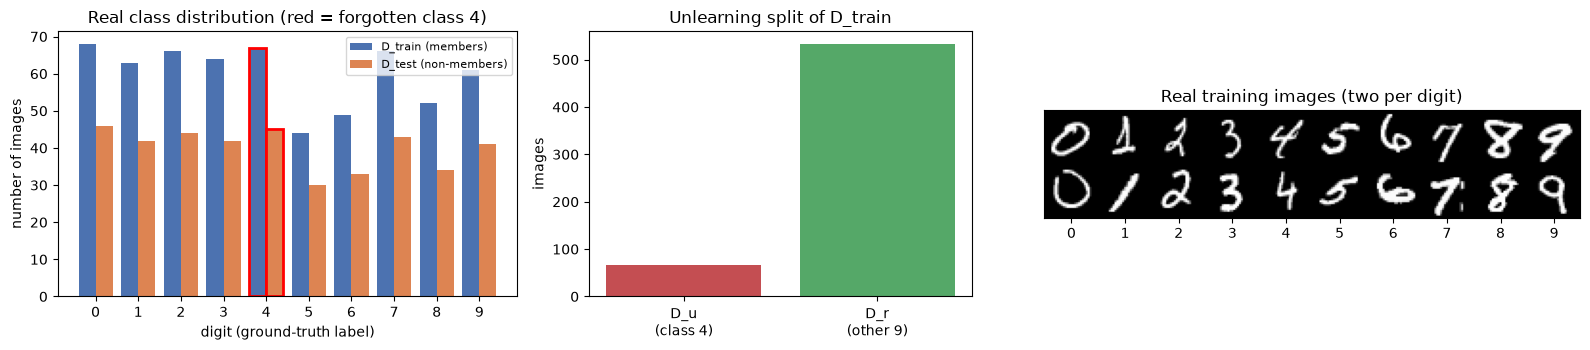

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1.4]))
w = 0.4; x_ = np.arange(10)
ax[0].bar(x_ - w / 2, cnt["train"], w, label="D_train (members)", color="#4C72B0")
ax[0].bar(x_ + w / 2, cnt["test"], w, label="D_test (non-members)", color="#DD8452")
ax[0].patches[c0].set_edgecolor("red"); ax[0].patches[c0].set_linewidth(2); ax[0].patches[10 + c0].set_edgecolor("red"); ax[0].patches[10 + c0].set_linewidth(2)
ax[0].set_xticks(x_); ax[0].set_xlabel("digit (ground-truth label)"); ax[0].set_ylabel("number of images")
ax[0].set_title(f"Real class distribution (red = forgotten class {c0})"); ax[0].legend(fontsize=8)
du_counts = [int(D0["tr_u"].sum()), int((~D0["tr_u"]).sum())]
ax[1].bar(["D_u\n(class %d)" % c0, "D_r\n(other 9)"], du_counts, color=["#C44E52", "#55A868"])
ax[1].set_title("Unlearning split of D_train"); ax[1].set_ylabel("images")
grid_img = np.zeros((2 * 28, 10 * 28))
for d in range(10):
    ids = np.where(D0["ytr"].numpy() == d)[0][:2]
    for k, i in enumerate(ids):
        grid_img[k * 28:(k + 1) * 28, d * 28:(d + 1) * 28] = D0["img_tr"][i, 0].numpy()
ax[2].imshow(grid_img, cmap="gray"); ax[2].set_xticks(np.arange(10) * 28 + 14); ax[2].set_xticklabels(range(10)); ax[2].set_yticks([])
ax[2].set_title("Real training images (two per digit)")
plt.tight_layout(); plt.show()

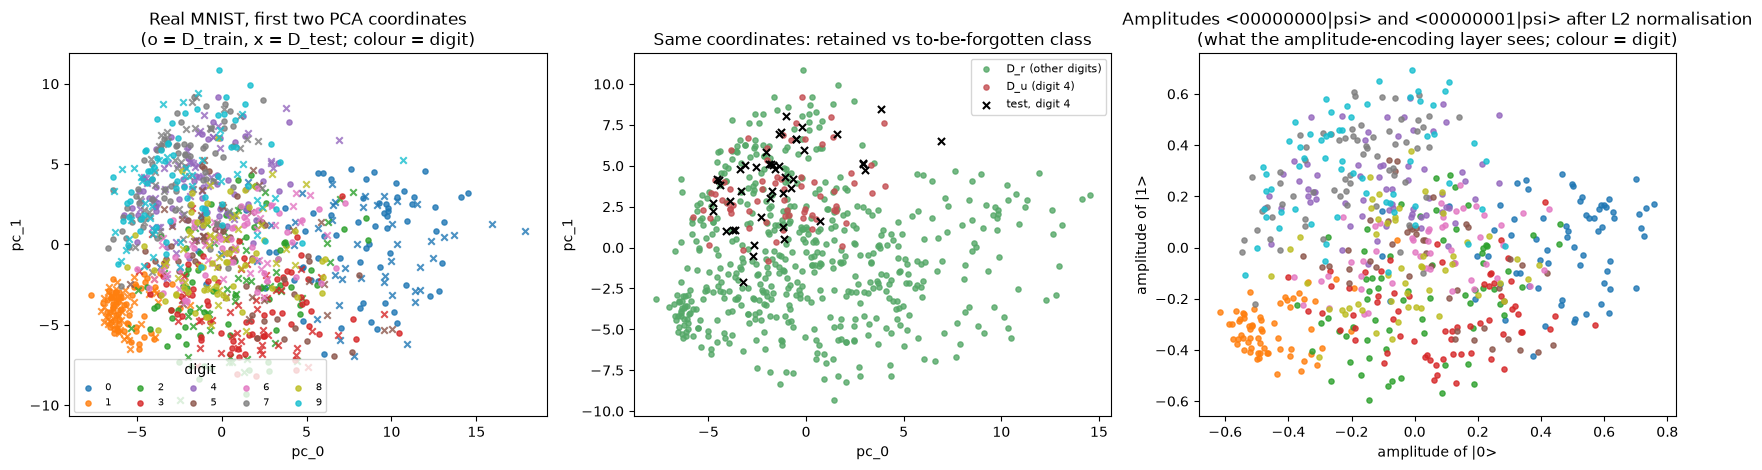

PCA explained variance of the 256 components kept (fitted on D_train): 99.1 %


In [11]:
# Raw PCA coordinates (PCA fitted on the training split only). MNIST is encoded in AMPLITUDES, not angles, so the
# "[0, pi] angle" version of this plot does not apply; instead we show the first two entries of the L2-normalised
# amplitude vector that the 8-qubit circuit actually receives.
Ptr, Pte = D0["pca_tr"].numpy(), D0["pca_te"].numpy()
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for d in range(10):
    m_tr, m_te = D0["ytr"].numpy() == d, D0["yte"].numpy() == d
    ax[0].scatter(Ptr[m_tr, 0], Ptr[m_tr, 1], s=14, color=cmap(d), label=str(d), alpha=0.8)
    ax[0].scatter(Pte[m_te, 0], Pte[m_te, 1], s=22, color=cmap(d), marker="x", alpha=0.8)
ax[0].set_title("Real MNIST, first two PCA coordinates\n(o = D_train, x = D_test; colour = digit)")
ax[0].set_xlabel("pc_0"); ax[0].set_ylabel("pc_1"); ax[0].legend(ncol=5, fontsize=7, title="digit", loc="lower left")
for name, m_, col in [("D_r (other digits)", ~D0["tr_u"].numpy(), "#55A868"), (f"D_u (digit {c0})", D0["tr_u"].numpy(), "#C44E52")]:
    ax[1].scatter(Ptr[m_, 0], Ptr[m_, 1], s=14, color=col, label=name, alpha=0.8)
ax[1].scatter(Pte[D0["te_u"].numpy(), 0], Pte[D0["te_u"].numpy(), 1], s=26, marker="x", color="k", label=f"test, digit {c0}")
ax[1].set_title("Same coordinates: retained vs to-be-forgotten class"); ax[1].set_xlabel("pc_0"); ax[1].set_ylabel("pc_1"); ax[1].legend(fontsize=8)
Atr = Ptr / np.linalg.norm(Ptr, axis=1, keepdims=True)
for d in range(10):
    m_tr = D0["ytr"].numpy() == d
    ax[2].scatter(Atr[m_tr, 0], Atr[m_tr, 1], s=14, color=cmap(d), alpha=0.8)
ax[2].set_title("Amplitudes <00000000|psi> and <00000001|psi> after L2 normalisation\n(what the amplitude-encoding layer sees; colour = digit)")
ax[2].set_xlabel("amplitude of |0>"); ax[2].set_ylabel("amplitude of |1>")
plt.tight_layout(); plt.show()
print("PCA explained variance of the 256 components kept (fitted on D_train): %.1f %%" % (100 * D0["pca"].explained_variance_ratio_.sum()))

## 3. Does the fast simulator equal the real PennyLane circuit?

We transcribe the authors' `qnode` (file `HQNN/HQNN.py`, commit `e557acc`) and run it, for real PennyLane `default.qubit`, on four inputs of each model. The assertion at the bottom
(difference below 1e-9) is what licenses using the fast simulator everywhere else.

In [12]:
from pennylane.templates.embeddings import AmplitudeEmbedding
dev_pl = qml.device("default.qubit", wires=NQ)

@qml.qnode(dev_pl, interface="torch")
def qnode(inputs, QNN_param):
    """Transcribed from HQNN/HQNN.py (commit e557acc): amplitude embedding, L x (U3 on all qubits + CNOT ring), <Z_i>."""
    AmplitudeEmbedding(inputs, wires=range(NQ), normalize=True)
    for k in range(QNN_param.shape[0]):
        for j in range(NQ):
            qml.U3(*QNN_param[k][j], wires=[j])
        for j in range(NQ - 1):
            qml.CNOT(wires=[j, j + 1])
        qml.CNOT(wires=[NQ - 1, 0])
    return [qml.expval(qml.PauliZ(i)) for i in range(NQ)]

def pennylane_features(model, x):
    """Run the REAL PennyLane circuit on the amplitude vector produced by `model`'s classical front end."""
    with torch.no_grad():
        a = model.pre(x)
        return torch.stack([torch.stack(qnode(ai / ai.norm(), model.QNN_param)) for ai in a])

demo_models = {"qnn": make_model("qnn", 0), "hqnn": make_model("hqnn", 0)}
for kind_, mdl in demo_models.items():
    xin = inputs(D0, kind_)[0][:4]
    ref = pennylane_features(mdl, xin); fast = mdl.m(xin).detach()
    err = (ref - fast).abs().max().item()
    assert err < 1e-9, err
    print(f"{kind_:5s}: fast PyTorch simulator == PennyLane default.qubit circuit, max |diff| of <Z_i> = {err:.2e}")

qnn  : fast PyTorch simulator == PennyLane default.qubit circuit, max |diff| of <Z_i> = 3.61e-16


hqnn : fast PyTorch simulator == PennyLane default.qubit circuit, max |diff| of <Z_i> = 3.89e-16


## Quantum Circuit Architecture

Both models run the **same** quantum layer: an 8-qubit, 5-layer hardware-efficient ansatz (U3 on every qubit, then a ring of CNOTs) preceded by amplitude encoding of 256 numbers and followed by Pauli-Z measurements on all 8 qubits. They differ only in the classical pre-processing that produces the 256 numbers (PCA for the basic QNN, a small CNN for the HQNN), so the circuit is drawn once per architecture with the real PennyLane QNode that the cells above proved equivalent to the simulator used for training.

Assumptions where the paper is silent (also listed in the table in section 0): the paper says "10-qubit" but its code uses 8 qubits (2^8 = 256 amplitudes, one `<Z>` per qubit feeding a `Linear(8,10)` classifier); the ansatz is `U3` rotations + a linear CNOT ring with a closing CNOT(7,0); amplitude encoding is the exact (Mottonen) state-preparation of PennyLane's `AmplitudeEmbedding`, which is drawn as a single box.

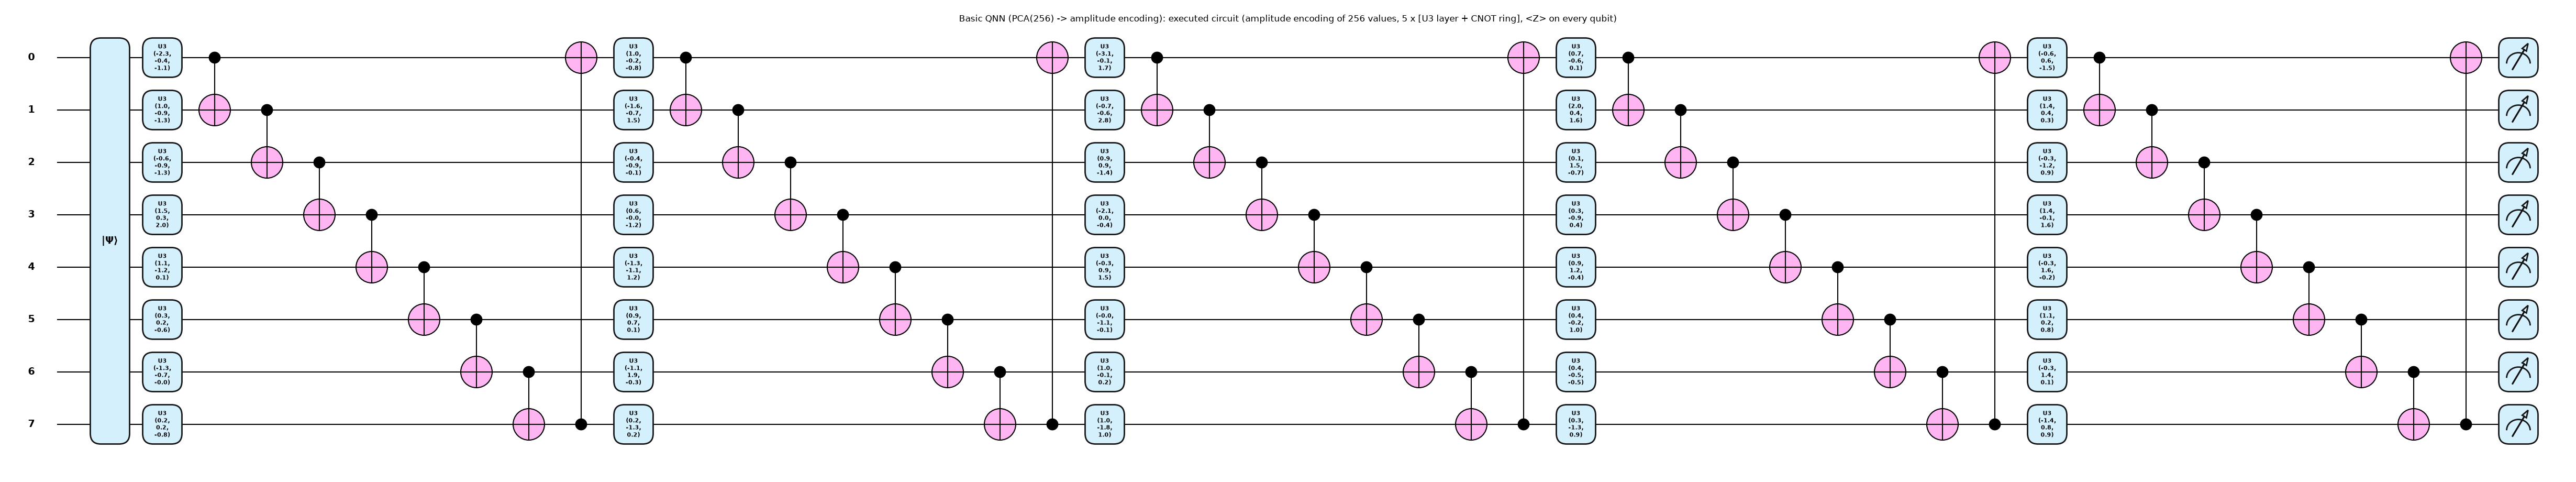

Basic QNN (PCA(256) -> amplitude encoding): qubits = 8 | depth (after decomposing to device gates) = 46 | gate counts = {'AmplitudeEmbedding': 1, 'U3': 40, 'CNOT': 40}
Basic QNN (PCA(256) -> amplitude encoding): trainable parameters: quantum ansatz = 120 (= 5 layers x 8 qubits x 3 angles), whole model = 210


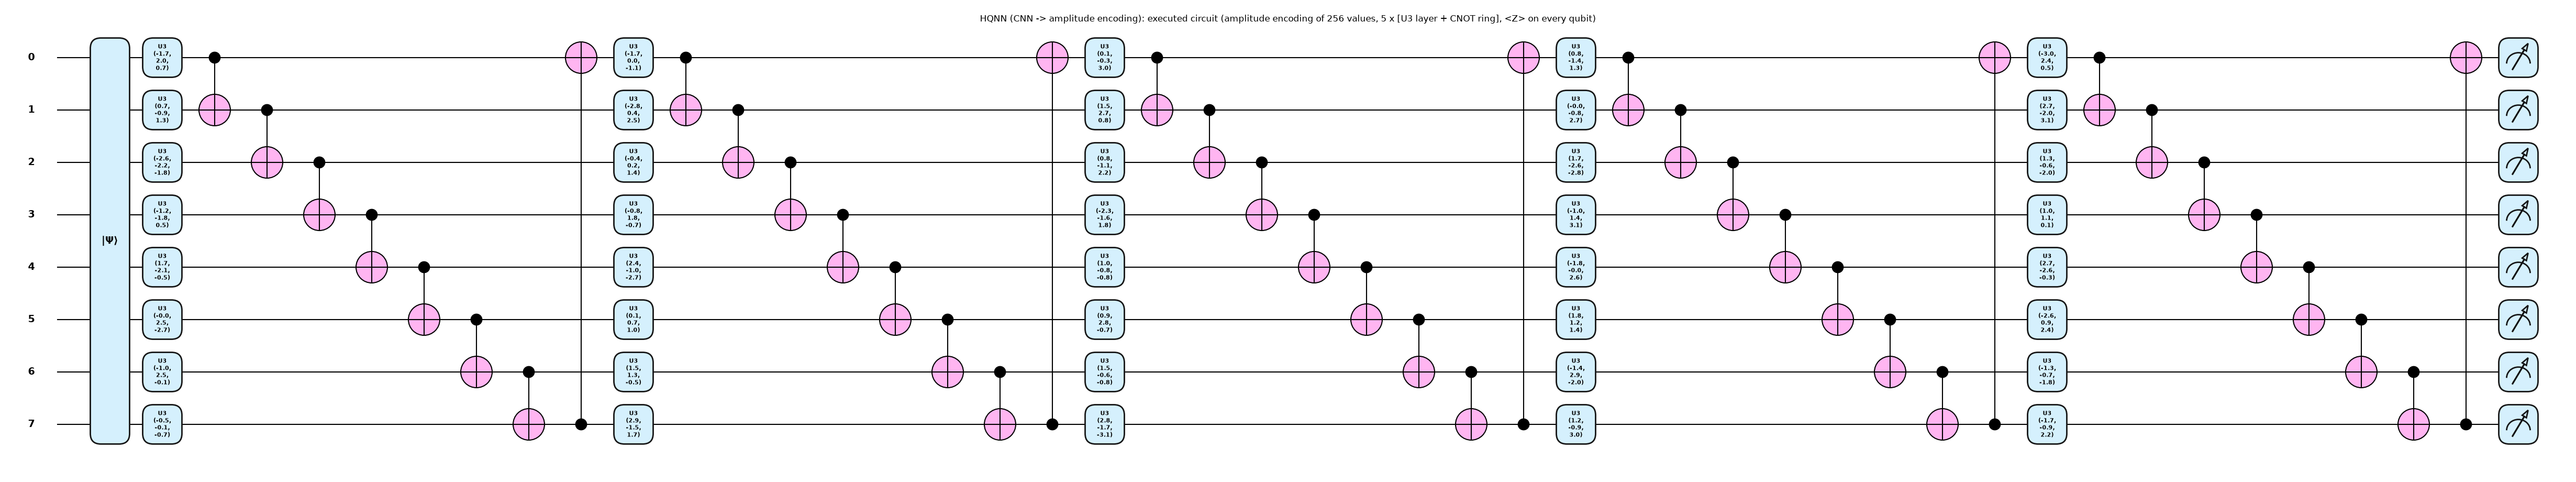

HQNN (CNN -> amplitude encoding): qubits = 8 | depth (after decomposing to device gates) = 46 | gate counts = {'AmplitudeEmbedding': 1, 'U3': 40, 'CNOT': 40}
HQNN (CNN -> amplitude encoding): trainable parameters: quantum ansatz = 120 (= 5 layers x 8 qubits x 3 angles), whole model = 251476


In [13]:
def circuit_report(kind_, title):
    mdl = demo_models[kind_]
    xin = inputs(D0, kind_)[0][:1]
    with torch.no_grad():
        a = mdl.pre(xin)[0]; a = a / a.norm()
    fig, ax = qml.draw_mpl(qnode, decimals=1, style="pennylane", fig_options=dict(figsize=(26, 6)))(a, mdl.QNN_param.detach())
    fig.suptitle(f"{title}: executed circuit (amplitude encoding of 256 values, 5 x [U3 layer + CNOT ring], <Z> on every qubit)", fontsize=12)
    plt.show()
    specs = qml.specs(qnode, level="device")(a, mdl.QNN_param.detach())
    res = specs.resources
    tot, qpar = n_params(mdl)
    print(f"{title}: qubits = {NQ} | depth (after decomposing to device gates) = {res.depth} | gate counts = {dict(res.gate_types)}")
    print(f"{title}: trainable parameters: quantum ansatz = {qpar} (= {N_LAYERS} layers x {NQ} qubits x 3 angles), whole model = {tot}")
circuit_report("qnn", "Basic QNN (PCA(256) -> amplitude encoding)")
circuit_report("hqnn", "HQNN (CNN -> amplitude encoding)")

### Cross-check with the authors' repository

If `git` and the network are available (they are on Colab), the repository is cloned at the pinned commit and (1) the authors' `ConvQNN` model is loaded with our weights and must give the same logits as our HQNN,
(2) the authors' `QCNN_circuit.QCNN(..., "Hardware_efficiency", ..., "Amplitude")` must give the same Z expectation values as our basic QNN, and (3) `qml.draw` of their QNode must be character-identical to ours.
The repository does not ship the unlearning methods SSD and RGA, the attack tables or the shot-noise study; those are implemented here from the paper's equations.

In [14]:
import subprocess, types
AUTHOR_OK = False
if USE_AUTHOR_REPO:
    try:
        repo_dir = os.path.join(DATA_DIR, "repos", "QMU")
        if not os.path.exists(repo_dir):
            os.makedirs(os.path.dirname(repo_dir), exist_ok=True)
            subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True, timeout=300)
        subprocess.run(["git", "-C", repo_dir, "checkout", "-q", REPO_COMMIT], check=True, timeout=60)
        sys.path.insert(0, os.path.join(repo_dir, "HQNN")); sys.path.insert(0, os.path.join(repo_dir, "QNN"))
        import HQNN as author_hqnn                      # the authors' ConvQNN (PennyLane TorchLayer + torch)
        import QCNN_circuit as author_qcnn              # the authors' basic-QNN circuit (Hardware_efficiency)
        # 1) HQNN: load OUR trained-shape weights into THEIR ConvQNN and compare logits
        theirs = author_hqnn.ConvQNN(types.SimpleNamespace(n_layers=N_LAYERS, n_qubit=NQ)).double()
        mine = demo_models["hqnn"]
        sd = {"conv1.weight": mine.conv1.weight, "conv1.bias": mine.conv1.bias, "fc1.weight": mine.fc1.weight, "fc1.bias": mine.fc1.bias,
              "fc2.weight": mine.fc2.weight, "fc2.bias": mine.fc2.bias, "qlayer.QNN_param": mine.QNN_param}
        theirs.load_state_dict({k: v.detach().clone() for k, v in sd.items()}, strict=True)
        xin = inputs(D0, "hqnn")[0][:3]
        with torch.no_grad():
            l_auth = theirs(xin); l_mine = mine(xin)
        print("authors' HQNN.ConvQNN forward vs our HQNN forward: max |logit diff| = %.2e" % (l_auth - l_mine).abs().max().item())
        assert (l_auth - l_mine).abs().max().item() < 1e-6
        # 2) basic QNN: their QCNN(...'Hardware_efficiency') circuit on a PCA vector vs ours
        a_ns = types.SimpleNamespace(n_layers=N_LAYERS, n_qubit=NQ, noise=False, total_params=NQ * 3)
        q = demo_models["qnn"]; xq = inputs(D0, "qnn")[0][0]
        res = author_qcnn.QCNN(a_ns, xq.numpy(), q.QNN_param.detach().reshape(-1).numpy(), "Hardware_efficiency", NQ * 3, "Amplitude", cost_fn="multi_cross_entropy")
        d2 = np.abs(np.array([float(r_) for r_ in res]) - q.m(xq[None]).detach().numpy()[0]).max()
        print("authors' QCNN_circuit.QCNN('Hardware_efficiency') vs our basic-QNN <Z_i>: max |diff| = %.2e" % d2)
        assert d2 < 1e-9
        # 3) drawing identical to their qnode
        a_demo = F.normalize(mine.pre(xin[:1]), dim=1)[0].detach()
        assert qml.draw(author_hqnn.qnode)(a_demo, mine.QNN_param.detach()) == qml.draw(qnode)(a_demo, mine.QNN_param.detach())
        print("qml.draw(authors' HQNN.qnode) == qml.draw(our qnode): True")
        AUTHOR_OK = True
    except Exception as e:
        print("Authors' repo cross-check skipped (needs git + network):", type(e).__name__, str(e)[:200])

authors' HQNN.ConvQNN forward vs our HQNN forward: max |logit diff| = 4.60e-10


authors' QCNN_circuit.QCNN('Hardware_efficiency') vs our basic-QNN <Z_i>: max |diff| = 1.11e-16
qml.draw(authors' HQNN.qnode) == qml.draw(our qnode): True


## 4. The membership inference attack and the unlearning methods

The attack follows Algorithm 1: query the model on known members (D_train) and non-members (D_test), record the output feature vector, train the 3-layer attack network, and report the share of
D_u samples that are declared "member". `fit_attack` builds three kinds of attacker: against A_o (members = all of D_train), against A_t (members = D_r only; D_u is then truly *not* a member),
and a **strict** variant of the A_o attacker that never sees a single sample of the forgotten class while it trains (an extra check not in the paper, it shows whether the leakage generalises to an unseen class).
`fit_acc` is the balanced accuracy of an attack on its own training data: when it is near 50 % the "success rate" is an artefact of a constant predictor.

In [15]:
FEATURES = ("loss", "logit", "softmax", "exp-values", "combo")

@torch.no_grad()
def api_outputs(model, X, y, shots=None, gen=None, bs=500):
    """What the gray-box adversary can read from the inference API for inputs X with known labels y (Sec. III.A.2)."""
    model.eval()
    m = torch.cat([model.m(X[i:i + bs], shots, gen) for i in range(0, len(X), bs)])   # estimated <Z_i>, one query per sample
    z = model.fc2(m); p = F.softmax(z, 1)
    loss = F.cross_entropy(z, y, reduction="none")[:, None]
    correct = (z.argmax(1) == y).double()[:, None]
    return {"exp-values": m, "logit": z, "softmax": p, "loss": loss,
            "combo": torch.cat([p, p.max(1, keepdim=True).values, correct, loss], 1)}   # authors' 13-d vector (MIA.py)

class AttackMLP(nn.Module):
    """3 fully-connected layers, ReLU, dropout 0.3 (paper Sec. III.B.1)."""
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        return self.net(x).squeeze(1)

class Attack:
    """Binary member / non-member classifier on API outputs. Standardiser and weights are fitted on the attack's own training data."""
    def __init__(self, feat, Fm, Fn, seed):
        self.feat = feat
        Z = torch.cat([Fm, Fn]); self.mu, self.sd = Z.mean(0), Z.std(0) + 1e-6
        t = torch.cat([torch.ones(len(Fm)), torch.zeros(len(Fn))])
        w = torch.cat([torch.full((len(Fm),), 0.5 / len(Fm)), torch.full((len(Fn),), 0.5 / len(Fn))]) * len(Z)   # class-balanced
        g = torch.Generator().manual_seed(seed); torch.manual_seed(seed)
        self.net = AttackMLP(Z.shape[1]); opt = torch.optim.Adam(self.net.parameters(), lr=ATTACK_LR)
        Zs = (Z - self.mu) / self.sd
        for ep in range(ATTACK_EPOCHS):
            self.net.train()
            for idx in batches(len(Zs), ATTACK_BS, g):
                opt.zero_grad()
                F.binary_cross_entropy_with_logits(self.net(Zs[idx]), t[idx], weight=w[idx]).backward(); opt.step()
        self.net.eval()
        with torch.no_grad():                                    # diagnostic: balanced accuracy of the attack on its own training data
            pr = self.net(Zs) > 0
            self.fit_acc = 0.5 * (pr[:len(Fm)].double().mean() + (~pr[len(Fm):]).double().mean()).item()
    @torch.no_grad()
    def is_member(self, Fx):
        return (self.net((Fx - self.mu) / self.sd) > 0)       # score = sigmoid(logit) > 0.5

def fit_attack(model, D, kind, feat, shots=None, gen=None, members="all", nonmembers="all"):
    """Adversary with labelled members / non-members of `model`'s training data (worst case, Algorithm 1).
    members="all": members = D_train (original model A_o);  members="retained": members = D_r only (target model A_t,
    which never saw D_u);  nonmembers="retained" additionally hides every class-c test sample from the attacker
    ("strict" variant: the attacker never sees the forgotten class at training time)."""
    Xtr, Xte = inputs(D, kind)
    mtr = torch.ones(len(Xtr), dtype=torch.bool) if members == "all" else ~D["tr_u"]
    mte = torch.ones(len(Xte), dtype=torch.bool) if nonmembers == "all" else ~D["te_u"]
    Fm = api_outputs(model, Xtr[mtr], D["ytr"][mtr], shots, gen)[feat]
    Fn = api_outputs(model, Xte[mte], D["yte"][mte], shots, gen)[feat]
    return Attack(feat, Fm, Fn, seed=D["seed"])
def mia_rate(attack, model, D, kind, shots=None, gen=None):
    """MIA success rate = fraction of D_u (class-c samples of D_train) that the attack declares 'member' when the
    query goes to `model` (paper: 100 samples of the unlearned class; here all class-c samples of D_train)."""
    Xtr, _ = inputs(D, kind); u = D["tr_u"]
    Fu = api_outputs(model, Xtr[u], D["ytr"][u], shots, gen)[attack.feat]
    return attack.is_member(Fu).double().mean().item()

The unlearning methods follow the equations of Sec. IV: GA (Eq. 9), empirical Fisher (Eq. 10), SSD (Eqs. 11-12) and RGA (Eq. 13), plus GD and the "-R" fine-tuning.
Hyper-parameter selection (SSD grid, GA/RGA stopping epoch) uses numbers measured on the **training** samples only.

In [16]:
def evaluate(model, D, kind, attack=None, shots=None, gen=None):
    """Acc_U / Acc_R on the test split (class c / all other classes), plus train-side numbers used for model selection."""
    Xtr, Xte = inputs(D, kind); ytr, yte = D["ytr"], D["yte"]
    out = dict(AccU=accuracy(model, Xte[D["te_u"]], yte[D["te_u"]], shots, gen),
               AccR=accuracy(model, Xte[~D["te_u"]], yte[~D["te_u"]], shots, gen),
               AccU_tr=accuracy(model, Xtr[D["tr_u"]], ytr[D["tr_u"]], shots, gen),
               AccR_tr=accuracy(model, Xtr[~D["tr_u"]], ytr[~D["tr_u"]], shots, gen))
    if attack is not None:
        out["MIA"] = mia_rate(attack, model, D, kind, shots, gen)
    return out

def split_train(D, kind):
    Xtr, _ = inputs(D, kind); u = D["tr_u"]
    return Xtr[u], D["ytr"][u], Xtr[~u], D["ytr"][~u]

def empirical_fisher(model, X, y):
    """Diagonal empirical Fisher: mean of squared per-sample gradients of the loss (Eq. 10)."""
    model.eval()
    params = [p for p in model.parameters() if p.requires_grad]
    Fd = [torch.zeros_like(p) for p in params]
    for i in range(len(X)):
        model.zero_grad()
        F.cross_entropy(model(X[i:i + 1]), y[i:i + 1]).backward()
        for f, p in zip(Fd, params):
            f += p.grad ** 2
    model.zero_grad()
    return [f / len(X) for f in Fd]

def ssd_apply(model, Fu, Fr, alpha, lam):
    """Selective Synaptic Dampening (Eq. 11-12): theta_i <- beta * theta_i where F_u[i] > alpha * F_r[i].
    CHOICE: beta = min(lam * F_r / F_u, 1) as in the original SSD paper; the paper's Eq. (12) prints F_u/F_r, which would
    never dampen for lam*alpha >= 1 and is taken to be a typo."""
    m2 = copy.deepcopy(model)
    with torch.no_grad():
        for p, fu, fr in zip([p for p in m2.parameters() if p.requires_grad], Fu, Fr):
            mask = fu > alpha * fr
            beta = torch.clamp(lam * fr / (fu + 1e-30), max=1.0)
            p.copy_(torch.where(mask, beta * p, p))
    return m2

def fine_tune_on_R(model, D, kind, gen, epochs=FT_EPOCHS, lr=FT_LR, bs=16):
    """The paper's "-R" variants: a short fine-tuning on D_r only."""
    _, _, Xr, yr = split_train(D, kind)
    m2 = copy.deepcopy(model); t0 = time.perf_counter()
    train_model(m2, Xr, yr, epochs, lr, bs, gen)
    return m2, time.perf_counter() - t0

def gradient_ascent(model, D, kind, lr, bs, epochs, gen, mask=None, shots=None, thr=0.02):
    """GA (Eq. 9): maximise the cross-entropy on D_u only. With `mask` (list of 0/1 tensors) it is RGA (Eq. 13).
    Returns the list of per-epoch snapshots (state dicts) and the cumulative training time (without evaluation)."""
    Xu, yu, _, _ = split_train(D, kind)
    m2 = copy.deepcopy(model); params = [p for p in m2.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=MOMENTUM)
    snaps, times, elapsed = [], [], 0.0; hit = None
    for ep in range(epochs):
        t0 = time.perf_counter(); m2.train()
        for idx in batches(len(Xu), bs, gen):
            opt.zero_grad()
            (-F.cross_entropy(m2(Xu[idx]), yu[idx])).backward()
            if mask is not None:
                for p, mk in zip(params, mask):
                    p.grad *= mk
            opt.step()
        elapsed += time.perf_counter() - t0
        snaps.append(copy.deepcopy(m2.state_dict())); times.append(elapsed)
        if hit is None and accuracy(m2, Xu, yu) <= thr:               # stopping rule (training samples of D_u only)
            hit = ep
        if hit is not None and ep + 1 >= max(UNL_MIN_EPOCHS, hit + 1 + UNL_EXTRA):
            break
    return m2, snaps, times

def pick_epoch(m2, snaps, D, kind, thr=0.02):
    """Stopping rule: first epoch at which accuracy on the training samples of D_u is <= thr (else the last epoch)."""
    for e, sd in enumerate(snaps):
        m2.load_state_dict(sd)
        if accuracy(m2, *split_train(D, kind)[:2]) <= thr:
            return e
    return len(snaps) - 1

def run_unlearning(D, kind, model_o, model_t, attack, gen, hp, verbose=False):
    """All methods of Table II for one run. Returns a DataFrame (one row per method) and the per-epoch GA/RGA curves."""
    Xu, yu, Xr, yr = split_train(D, kind)
    rows, curves = [], {}
    def row(name, model, secs):
        r = dict(Method=name, **evaluate(model, D, kind, attack), time_s=secs); rows.append(r); return r
    row("A_o", model_o, np.nan); row("A_t", model_t, np.nan)
    # --- GD baseline: keep training on D_r only
    m = copy.deepcopy(model_o); t0 = time.perf_counter()
    train_model(m, Xr, yr, GD_EPOCHS, hp["gd_lr"], hp["gd_bs"], gen)
    row("GD", m, time.perf_counter() - t0)
    # --- GA (needs D_u only)
    mga, snaps, times = gradient_ascent(model_o, D, kind, hp["ga_lr"], hp["ga_bs"], UNL_EPOCHS, gen)
    curve = []
    for e, sd in enumerate(snaps):
        mga.load_state_dict(sd); curve.append(dict(epoch=e + 1, **evaluate(mga, D, kind, attack)))
    curves["GA"] = pd.DataFrame(curve)
    e = pick_epoch(mga, snaps, D, kind); mga.load_state_dict(snaps[e]); row("GA", mga, times[e]); rows[-1]["epoch"] = e + 1
    mr, tft = fine_tune_on_R(mga, D, kind, gen); row("GA-R", mr, times[e] + tft)
    # --- Fisher information (needed by SSD and RGA; both read D_r and D_u)
    t0 = time.perf_counter(); Fu = empirical_fisher(model_o, Xu, yu); Fr = empirical_fisher(model_o, Xr, yr)
    t_fisher = time.perf_counter() - t0
    # --- SSD: grid over (alpha, lambda); model selection uses train-side numbers only
    grid = []
    for a in hp["ssd_alphas"]:
        for lam in hp["ssd_lambdas"]:
            t0 = time.perf_counter(); ms = ssd_apply(model_o, Fu, Fr, a, lam); ts = time.perf_counter() - t0
            grid.append(dict(alpha=a, lam=lam, time_s=t_fisher + ts, **evaluate(ms, D, kind, attack)))
    grid = pd.DataFrame(grid)
    score = grid["AccU_tr"] + grid["MIA"]
    ok = grid[score <= score.min() + 0.02]
    best = ok.loc[ok["AccR_tr"].idxmax()]
    ms = ssd_apply(model_o, Fu, Fr, best["alpha"], best["lam"]); row(f"SSD", ms, best["time_s"])
    rows[-1]["alpha"], rows[-1]["lam"] = best["alpha"], best["lam"]
    mssdr, tft = fine_tune_on_R(ms, D, kind, gen); row("SSD-R", mssdr, best["time_s"] + tft)
    # --- RGA: gradient ascent restricted to parameters with F_u > alpha F_r
    mask = [(fu > hp["rga_alpha"] * fr).double() for fu, fr in zip(Fu, Fr)]
    mrga, snaps, times = gradient_ascent(model_o, D, kind, hp["rga_lr"], hp["rga_bs"], UNL_EPOCHS, gen, mask=mask)
    curve = []
    for e, sd in enumerate(snaps):
        mrga.load_state_dict(sd); curve.append(dict(epoch=e + 1, **evaluate(mrga, D, kind, attack)))
    curves["RGA"] = pd.DataFrame(curve)
    e = pick_epoch(mrga, snaps, D, kind); mrga.load_state_dict(snaps[e]); row("RGA", mrga, t_fisher + times[e]); rows[-1]["epoch"] = e + 1
    mr, tft = fine_tune_on_R(mrga, D, kind, gen); row("RGA-R", mr, t_fisher + times[e] + tft)
    rows[-1]["masked_frac"] = float(sum(m_.sum() for m_ in mask) / sum(m_.numel() for m_ in mask))
    return pd.DataFrame(rows), curves, grid

Finite-shot versions (used in section 8): the forward value is an N-shot estimate, the gradient of each ansatz angle is the parameter-shift rule evaluated with N shots per shifted circuit
(exact for `U3` angles; the unit test in section 8 compares our shift implementation with autograd), and the Fisher information is built from the same noisy gradients.

In [17]:
def _batched_kron(G):
    """G: [n, NQ, 2, 2] -> [n, DIM, DIM] Kronecker products over the qubit axis."""
    K = G[:, 0]
    for j in range(1, NQ):
        a = K.shape[-1]
        K = torch.einsum("nab,ncd->nacbd", K, G[:, j]).reshape(K.shape[0], a * 2, a * 2)
    return K

@torch.no_grad()
def ps_jacobian(amp, W, shots=None, gen=None, chunk=300):
    """Parameter-shift Jacobian D[p, b, q] = ( m_q(theta_p + pi/2) - m_q(theta_p - pi/2) ) / 2 for every ansatz angle p.
    Every U3 angle is a Pauli-rotation angle, so this rule is exact. With `shots`, each of the 2 x 120 shifted circuits is
    estimated from that many measurement shots (this is how the gradients on a real device look)."""
    L = W.shape[0]; P = L * NQ * 3
    out = torch.zeros(P, amp.shape[0], NQ)
    for s0 in range(0, amp.shape[0], chunk):
        a = amp[s0:s0 + chunk]
        Ks = [layer_unitary(W[k]) for k in range(L)]
        pre = [torch.complex(a, torch.zeros_like(a))]
        for k in range(L):
            pre.append((pre[-1] @ Ks[k].T)[:, RING_INV])
        for k in range(L):
            Wk = W[k].reshape(1, NQ, 3).repeat(NQ * 3 * 2, 1, 1)
            for pi in range(NQ * 3):
                Wk[2 * pi].view(-1)[pi] += np.pi / 2
                Wk[2 * pi + 1].view(-1)[pi] -= np.pi / 2
            K = _batched_kron(u3_mats(Wk))                                   # [48, DIM, DIM]
            psi = torch.einsum("bj,nij->nbi", pre[k], K)[:, :, RING_INV]     # [48, B, DIM]
            for l in range(k + 1, L):
                psi = (psi @ Ks[l].T)[:, :, RING_INV]
            pr = (psi.real ** 2 + psi.imag ** 2)                              # [48, B, DIM]
            if shots is None:
                m = pr @ ZSIGN
            else:
                m = sample_expvals(pr.reshape(-1, DIM), shots, gen).reshape(pr.shape[0], pr.shape[1], NQ)
            d = (m[0::2] - m[1::2]) / 2                                       # [24, B, NQ]
            out[k * NQ * 3:(k + 1) * NQ * 3, s0:s0 + chunk] = d
    return out

def noisy_loss_grads(model, X, y, shots, gen, sign=1.0):
    """Fill .grad of every parameter for  sign * CE  when the quantum layer is only available through `shots`-shot estimates:
    forward value = finite-shot <Z>; gradient of the ansatz angles = parameter-shift with finite shots;
    gradient flowing back into the classical pre-processing = analytic Jacobian of the exact circuit (CHOICE)."""
    model.zero_grad(); W = model.QNN_param
    amp = model.amp(X)
    p = quantum_probs(amp, W.detach()); m_exact = expvals_from_probs(p)
    m_hat = sample_expvals(p, shots, gen)
    m = m_exact + (m_hat - m_exact).detach(); m.retain_grad()
    (sign * F.cross_entropy(model.fc2(m), y)).backward()
    D = ps_jacobian(amp.detach(), W.detach(), shots, gen)
    W.grad = torch.einsum("pbq,bq->p", D, m.grad).view_as(W)

def empirical_fisher_shots(model, X, y, shots, gen):
    """Diagonal empirical Fisher when the circuit is only accessible through `shots`-shot estimates (see noisy_loss_grads)."""
    model.eval(); W = model.QNN_param
    params = [p for p in model.parameters() if p.requires_grad]
    with torch.no_grad():
        amp = model.amp(X); p = quantum_probs(amp, W); m_hat = sample_expvals(p, shots, gen)
    m_leaf = m_hat.clone().requires_grad_(True)
    losses = F.cross_entropy(model.fc2(m_leaf), y, reduction="none")
    g_m, = torch.autograd.grad(losses.sum(), m_leaf)                          # per-sample dL_b/dm_b
    D = ps_jacobian(amp, W.detach(), shots, gen)
    fW = (torch.einsum("pbq,bq->bp", D, g_m) ** 2).mean(0).view_as(W)
    Fd = [torch.zeros_like(q) for q in params]
    for i in range(len(X)):                                                  # classical layers: one backward per sample
        model.zero_grad()
        a_i = model.amp(X[i:i + 1]); me = expvals_from_probs(quantum_probs(a_i, W.detach()))
        mi = me + (m_hat[i:i + 1] - me).detach()
        F.cross_entropy(model.fc2(mi), y[i:i + 1]).backward()
        for f, q in zip(Fd, params):
            if q is not W and q.grad is not None:
                f += q.grad ** 2
    model.zero_grad()
    Fd = [f / len(X) for f in Fd]
    return [fW if q is W else f for f, q in zip(Fd, params)]

def gradient_ascent_shots(model, D, kind, lr, bs, epochs, gen, shots):
    """GA with finite-shot gradients (Sec. IV.B.3). Returns the list of per-epoch models."""
    Xu, yu, _, _ = split_train(D, kind)
    m2 = copy.deepcopy(model); params = [p for p in m2.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=MOMENTUM); snaps = []
    for ep in range(epochs):
        m2.train()
        for idx in batches(len(Xu), bs, gen):
            opt.zero_grad(); noisy_loss_grads(m2, Xu[idx], yu[idx], shots, gen, sign=-1.0); opt.step()
        snaps.append(copy.deepcopy(m2.state_dict()))
    return m2, snaps

def shot_noise_unlearning(D, kind, model_o, hp, ssd_ab, shots_list, gen, fisher_n=None, epochs=4):
    """Fig. 6 / Fig. 7 analogue for one run: A_o is trained analytically, the adversary and the unlearner only see N-shot outputs."""
    Xu, yu, Xr, yr = split_train(D, kind); rows_ga, rows_ssd = [], []
    if fisher_n is not None and fisher_n < len(Xr):                                   # CHOICE: cheaper N-shot Fisher on a random subset of D_r
        sub = torch.randperm(len(Xr), generator=gen)[:fisher_n]; Xr_f, yr_f = Xr[sub], yr[sub]
    else:
        Xr_f, yr_f = Xr, yr
    att_ideal = fit_attack(model_o, D, kind, "combo")
    ideal = evaluate(model_o, D, kind, att_ideal)
    Fu_ideal = empirical_fisher(model_o, Xu, yu); Fr_ideal = empirical_fisher(model_o, Xr, yr)
    m_ideal_ssd = ssd_apply(model_o, Fu_ideal, Fr_ideal, *ssd_ab)
    ideal_ssd = evaluate(m_ideal_ssd, D, kind, att_ideal)
    # analytic reference trajectory of the same GA (shots = 0 stands for "infinitely many shots"); thr=-1 disables the early stop
    m_a, snaps_a, _ = gradient_ascent(model_o, D, kind, hp["ga_lr"], hp["ga_bs"], epochs, gen, thr=-1.0)
    rows_ga.append(dict(shots=0, epoch=0, **ideal))
    for e, sd in enumerate(snaps_a):
        m_a.load_state_dict(sd); rows_ga.append(dict(shots=0, epoch=e + 1, **evaluate(m_a, D, kind, att_ideal)))
    for N in shots_list:
        att = fit_attack(model_o, D, kind, "combo", shots=N, gen=gen)                # adversary only sees N-shot API outputs
        # --- GA with N-shot gradients
        m2, snaps = gradient_ascent_shots(model_o, D, kind, hp["ga_lr"], hp["ga_bs"], epochs, gen, N)
        rows_ga.append(dict(shots=N, epoch=0, **evaluate(model_o, D, kind, att, N, gen)))
        for e, sd in enumerate(snaps):
            m2.load_state_dict(sd); rows_ga.append(dict(shots=N, epoch=e + 1, **evaluate(m2, D, kind, att, N, gen)))
        # --- SSD with N-shot Fisher information
        Fu = empirical_fisher_shots(model_o, Xu, yu, N, gen); Fr = empirical_fisher_shots(model_o, Xr_f, yr_f, N, gen)
        ms = ssd_apply(model_o, Fu, Fr, *ssd_ab)
        rows_ssd.append(dict(shots=N, **evaluate(ms, D, kind, att, N, gen)))
    return pd.DataFrame(rows_ga), pd.DataFrame(rows_ssd), ideal, ideal_ssd

## 5. Training the original models A_o and the retrained targets A_t, and the classical baselines

In [18]:
TRAIN_CFG = {"qnn":  dict(epochs=EPOCHS_QNN,  lr=LR_QNN,  bs=BS_QNN,  nesterov=True),
             "hqnn": dict(epochs=EPOCHS_HQNN, lr=LR_HQNN, bs=BS_HQNN, nesterov=False)}
ARCH_NAME = {"qnn": "Basic QNN", "hqnn": "HQNN"}

def train_pair(D, kind):
    """A_o: trained on all of D_train.  A_t: retrained from scratch on D_r only (the ideal, expensive unlearning baseline)."""
    cfg = TRAIN_CFG[kind]; Xtr, Xte = inputs(D, kind)
    gen = torch.Generator().manual_seed(D["seed"] + 7)
    mo = make_model(kind, D["seed"])
    h_o = train_model(mo, Xtr, D["ytr"], cfg["epochs"], cfg["lr"], cfg["bs"], gen, cfg["nesterov"], Xte, D["yte"])
    _, _, Xr, yr = split_train(D, kind)
    mt = make_model(kind, D["seed"] + 1000)
    h_t = train_model(mt, Xr, yr, cfg["epochs"], cfg["lr"], cfg["bs"], gen, cfg["nesterov"], Xte[~D["te_u"]], D["yte"][~D["te_u"]])
    return mo, mt, h_o, h_t

RUNS = {}            # (run, kind) -> dict(D, mo, mt, h_o, h_t)
DATA = {}
t_start_all = time.time()
for r in range(N_RUNS):
    DATA[r] = D = prepare_run(r)
    for kind in ("qnn", "hqnn"):
        t0 = time.time(); mo, mt, h_o, h_t = train_pair(D, kind)
        RUNS[(r, kind)] = dict(mo=mo, mt=mt, h_o=h_o, h_t=h_t)
        ev_o = evaluate(mo, D, kind); ev_t = evaluate(mt, D, kind)
        print(f"run {r} | forget digit {D['c']} | {ARCH_NAME[kind]:9s} | A_o: train acc {h_o['train_acc'][-1]:.3f}, AccU {ev_o['AccU']:.3f}, AccR {ev_o['AccR']:.3f} "
              f"| A_t: AccU {ev_t['AccU']:.3f}, AccR {ev_t['AccR']:.3f} | train time A_o {h_o['time']:.0f}s, A_t {h_t['time']:.0f}s | total {time.time()-t0:.0f}s")

run 0 | forget digit 4 | Basic QNN | A_o: train acc 0.575, AccU 0.333, AccR 0.501 | A_t: AccU 0.000, AccR 0.639 | train time A_o 119s, A_t 91s | total 211s


run 0 | forget digit 4 | HQNN      | A_o: train acc 1.000, AccU 0.956, AccR 0.935 | A_t: AccU 0.000, AccR 0.924 | train time A_o 59s, A_t 83s | total 142s


run 1 | forget digit 5 | Basic QNN | A_o: train acc 0.603, AccU 0.415, AccR 0.560 | A_t: AccU 0.000, AccR 0.588 | train time A_o 178s, A_t 92s | total 270s


run 1 | forget digit 5 | HQNN      | A_o: train acc 1.000, AccU 0.951, AccR 0.933 | A_t: AccU 0.000, AccR 0.939 | train time A_o 66s, A_t 59s | total 126s


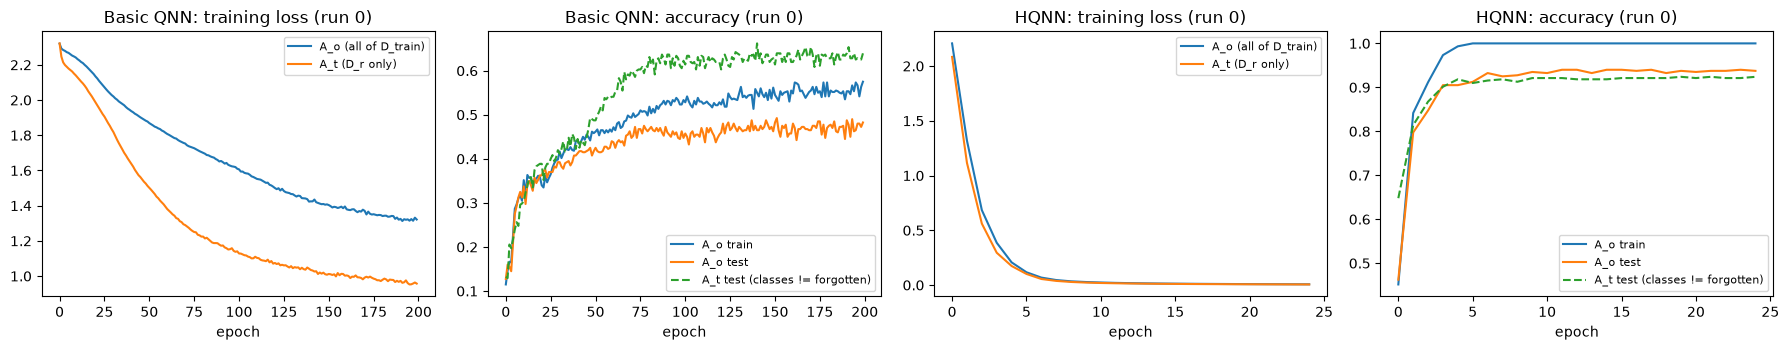

In [19]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for k_, kind in enumerate(("qnn", "hqnn")):
    R = RUNS[(0, kind)]
    ax[2 * k_].plot(R["h_o"]["loss"], label="A_o (all of D_train)"); ax[2 * k_].plot(R["h_t"]["loss"], label="A_t (D_r only)")
    ax[2 * k_].set_title(f"{ARCH_NAME[kind]}: training loss (run 0)"); ax[2 * k_].set_xlabel("epoch"); ax[2 * k_].legend(fontsize=8)
    ax[2 * k_ + 1].plot(R["h_o"]["train_acc"], label="A_o train"); ax[2 * k_ + 1].plot(R["h_o"]["val_acc"], label="A_o test")
    ax[2 * k_ + 1].plot(R["h_t"]["val_acc"], "--", label="A_t test (classes != forgotten)")
    ax[2 * k_ + 1].set_title(f"{ARCH_NAME[kind]}: accuracy (run 0)"); ax[2 * k_ + 1].set_xlabel("epoch"); ax[2 * k_ + 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Classical baselines on identical inputs

Random Forest and an RBF SVM on the same 256 L2-normalised PCA vectors that the basic QNN's qubits receive, and a *classical twin* of the HQNN (same CNN, quantum layer replaced by a classical 256 -> 8 tanh layer).
We also attack the twin: it shows that membership leakage is not special to quantum models (the paper does not make this comparison).

In [20]:
D = DATA[0]; rows_b = []
Ptr_, Pte_ = D["pca_tr"].numpy(), D["pca_te"].numpy(); ytr_, yte_ = D["ytr"].numpy(), D["yte"].numpy()
Xs_tr = Ptr_ / np.linalg.norm(Ptr_, axis=1, keepdims=True); Xs_te = Pte_ / np.linalg.norm(Pte_, axis=1, keepdims=True)   # same L2-normalised vectors the qubits receive
for name, clf in [("RandomForest (256 L2-normalised PCA inputs)", RandomForestClassifier(n_estimators=200, random_state=D["seed"], n_jobs=1)),
                  ("SVC rbf (256 L2-normalised PCA inputs)", SVC(kernel="rbf", C=10, gamma="scale"))]:
    t0 = time.perf_counter(); clf.fit(Xs_tr, ytr_)
    rows_b.append(dict(model=name, train_acc=clf.score(Xs_tr, ytr_), test_acc=clf.score(Xs_te, yte_), time_s=time.perf_counter() - t0))
for kind in ("qnn", "hqnn"):
    R = RUNS[(0, kind)]; Xtr, Xte = inputs(D, kind)
    rows_b.append(dict(model=f"{ARCH_NAME[kind]} (quantum, A_o)", train_acc=accuracy(R["mo"], Xtr, D["ytr"]), test_acc=accuracy(R["mo"], Xte, D["yte"]), time_s=R["h_o"]["time"]))
# classical twin of the HQNN: same CNN front end, quantum layer replaced by a classical 256->8 tanh layer
gen_c = torch.Generator().manual_seed(D["seed"] + 7); twin = make_model("classical", D["seed"])
h_c = train_model(twin, D["img_tr"], D["ytr"], EPOCHS_HQNN, LR_HQNN, BS_HQNN, gen_c)
rows_b.append(dict(model="Classical twin of HQNN (CNN + classical 8-unit layer)", train_acc=accuracy(twin, D["img_tr"], D["ytr"]), test_acc=accuracy(twin, D["img_te"], D["yte"]), time_s=h_c["time"]))
baseline_df = pd.DataFrame(rows_b); print(baseline_df.round(3).to_string(index=False))
twin_mia = {}
for feat in ("loss", "logit", "softmax"):
    att = fit_attack(twin, D, "classical", feat); twin_mia[feat] = mia_rate(att, twin, D, "classical")
print("Membership leakage of the classical twin (attack success on D_u members, worst case):", {k: round(v, 3) for k, v in twin_mia.items()})

                                                model  train_acc  test_acc  time_s
          RandomForest (256 L2-normalised PCA inputs)      1.000     0.770   3.665
               SVC rbf (256 L2-normalised PCA inputs)      1.000     0.925   0.511
                             Basic QNN (quantum, A_o)      0.575     0.482 119.148
                                  HQNN (quantum, A_o)      1.000     0.938  58.602
Classical twin of HQNN (CNN + classical 8-unit layer)      1.000     0.910  28.278


Membership leakage of the classical twin (attack success on D_u members, worst case): {'loss': 1.0, 'logit': 0.0, 'softmax': 0.0}


## 6. Do the QNNs leak membership? (paper Sec. III, Table I)

For each architecture and each run we build the three attacks of Algorithm 1 for every output feature the gray-box API exposes:

* **A_o column**: attack trained on the original model's outputs (members = all of `D_train`, non-members = `D_test`), then asked about the samples of the class that is going to be forgotten (`D_u`, taken from `D_train`, so they are true members of A_o). *Success rate* = fraction declared "member" (higher = more leakage).
* **A_t column**: the same attack pipeline against the retrained target model, whose members are `D_r` only, so every `D_u` sample is a true non-member (here the success rate should be near 0).
* **A_o strict** (extra, not in the paper): the attacker never sees any sample of the forgotten class while training the attack, so the number measures how much the leakage generalises to an unseen class instead of being memorised by the attack MLP.

`exp-values` are the eight `<Z_i>` estimated from 4096 shots in our noiseless simulator; the paper's `exp-values` rows come from the Tianyan-504 superconducting device and **cannot be reproduced here**.

In [21]:
def table1_rows(D, kind, mo, mt):
    gen = torch.Generator().manual_seed(D["seed"] + 11); rows = []
    for feat in ("loss", "logit", "softmax", "exp-values"):
        sh = SHOTS_API if feat == "exp-values" else None
        a_o = fit_attack(mo, D, kind, feat, sh, gen, "all", "all")
        a_t = fit_attack(mt, D, kind, feat, sh, gen, "retained", "all")
        a_s = fit_attack(mo, D, kind, feat, sh, gen, "retained", "retained")
        rows.append(dict(run=D["r"], arch=ARCH_NAME[kind], feature=feat, A_o=100 * mia_rate(a_o, mo, D, kind, sh, gen),
                         A_t=100 * mia_rate(a_t, mt, D, kind, sh, gen), A_o_strict=100 * mia_rate(a_s, mo, D, kind, sh, gen), fit_acc_A_o=100 * a_o.fit_acc))
    return rows

t0 = time.time(); t1_rows = []
for (r, kind), R in RUNS.items():
    t1_rows += table1_rows(DATA[r], kind, R["mo"], R["mt"])
T1 = pd.DataFrame(t1_rows)
T1_mean = T1.groupby(["arch", "feature"], sort=False)[["A_o", "A_t", "A_o_strict", "fit_acc_A_o"]].agg(["mean", "std"]).round(1)
print(f"Table I (this notebook): MIA success rate in %, mean/std over {N_RUNS} run(s)   [{time.time()-t0:.0f}s]")
print(T1_mean.to_string())

Table I (this notebook): MIA success rate in %, mean/std over 2 run(s)   [1678s]
                       A_o         A_t       A_o_strict       fit_acc_A_o     
                      mean   std  mean   std       mean   std        mean  std
arch      feature                                                             
Basic QNN loss        82.4   8.9   0.0   0.0       80.9   8.8        55.0  2.1
          logit       30.3   2.8  34.9  30.4       47.6  67.3        57.9  0.4
          softmax     94.0   6.2  39.0  20.9       32.5  32.2        55.9  3.6
          exp-values  57.4  28.4  50.5  23.5       52.1  35.7        62.9  3.7
HQNN      loss        96.1   1.3   0.0   0.0       97.6   1.2        67.6  0.8
          logit       98.5   2.1   1.6   2.3        0.0   0.0        60.4  5.5
          softmax     50.0  70.7   1.6   2.3        0.0   0.0        53.0  5.1
          exp-values  98.5   2.1   2.4   1.2       48.4  68.4        63.5  5.2


### Fig. 3 analogue: shot noise at inference

The HQNN is trained analytically. The attacker and the accuracy measurement then see only N-shot estimates (one query per sample). The paper reports MIA success falling from about 94 % to 67 % and accuracy from 96 % to 89 % at N = 16.

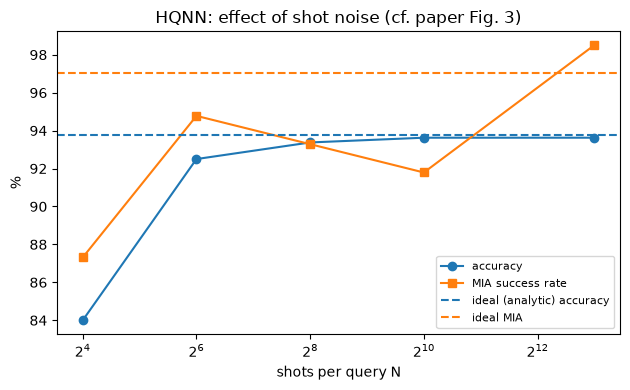

accuracy as a fraction; MIA and fit_acc (balanced accuracy of the attack on its own training data) in %; analytic reference: acc 0.938, MIA 97.0, fit_acc 69.2
        acc          MIA       fit_acc      
       mean   std   mean   std    mean   std
shots                                       
16     0.84  0.01  87.31  9.50   59.73  0.80
64     0.92  0.01  94.78  1.06   63.96  0.71
256    0.93  0.01  93.28  3.17   66.60  0.09
1024   0.94  0.00  91.79  7.39   69.21  0.35
8192   0.94  0.00  98.51  0.00   69.56  0.15
[177s]


In [22]:
def shot_sweep(D, mo, shots_grid=SHOT_GRID_SWEEP, repeats=SWEEP_REPEATS):
    gen = torch.Generator().manual_seed(D["seed"] + 21); Xtr, Xte = inputs(D, "hqnn"); rows = []
    att_ideal = fit_attack(mo, D, "hqnn", "combo")
    rows.append(dict(shots="analytic", acc=accuracy(mo, Xte, D["yte"]), MIA=100 * mia_rate(att_ideal, mo, D, "hqnn"), fit_acc=100 * att_ideal.fit_acc))
    for N in shots_grid:
        for rep in range(repeats):
            att = fit_attack(mo, D, "hqnn", "combo", N, gen)             # the attacker only ever sees N-shot answers (one query per sample)
            rows.append(dict(shots=N, rep=rep, acc=accuracy(mo, Xte, D["yte"], N, gen), MIA=100 * mia_rate(att, mo, D, "hqnn", N, gen), fit_acc=100 * att.fit_acc))
    return rows

t0 = time.time(); sweep = []
for r in range(N_RUNS_SWEEP):
    sweep += [dict(run=r, **row) for row in shot_sweep(DATA[r], RUNS[(r, "hqnn")]["mo"])]
SW = pd.DataFrame(sweep)
ideal_sw = SW[SW.shots == "analytic"][["acc", "MIA", "fit_acc"]].mean()
SWm = SW[SW.shots != "analytic"].astype({"shots": int}).groupby("shots")[["acc", "MIA", "fit_acc"]].agg(["mean", "std"])
fig, ax = plt.subplots(1, 1, figsize=(6.4, 4))
ax.plot(SWm.index, 100 * SWm[("acc", "mean")] , "o-", color="C0", label="accuracy")
ax.plot(SWm.index, SWm[("MIA", "mean")], "s-", color="C1", label="MIA success rate")
ax.axhline(100 * ideal_sw["acc"], color="C0", ls="--", label="ideal (analytic) accuracy"); ax.axhline(ideal_sw["MIA"], color="C1", ls="--", label="ideal MIA")
ax.set_xscale("log", base=2); ax.set_xlabel("shots per query N"); ax.set_ylabel("%"); ax.set_title("HQNN: effect of shot noise (cf. paper Fig. 3)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("accuracy as a fraction; MIA and fit_acc (balanced accuracy of the attack on its own training data) in %; analytic reference: "
      f"acc {ideal_sw['acc']:.3f}, MIA {ideal_sw['MIA']:.1f}, fit_acc {ideal_sw['fit_acc']:.1f}")
print(SWm.round(2).to_string()); print(f"[{time.time()-t0:.0f}s]")

## 7. Quantum Machine Unlearning (paper Sec. IV, Table II, Fig. 5)

Methods, all implemented from the paper's equations (the authors' repository only ships GD/GA drivers):

| Method | What it does | Needs |
|---|---|---|
| **GD** | keep training on `D_r` only (baseline) | `D_r` |
| **GA** | gradient *ascent* on the cross-entropy of `D_u` (Eq. 9) | `D_u` only |
| **SSD** | Fisher-based selective dampening of parameters with `F_u > alpha F_r` (Eq. 10-12) | `D_u`, `D_r` |
| **RGA** | gradient ascent restricted to those parameters (Eq. 13) | `D_u`, `D_r` |
| **-R** | the same followed by 1 epoch of fine-tuning on `D_r` | `D_r` |

Metrics: `Acc_U` (test samples of the forgotten class), `Acc_R` (test samples of all other classes), MIA success rate on `D_u` (attack = the combined 13-d feature vector of the authors' `MIA.py`, trained once on A_o), wall-clock seconds (SSD/RGA include the two Fisher passes). The SSD grid and the GA/RGA stopping epoch are chosen on **training-side** numbers only. Reference rows: `A_o` (original), `A_t` (retrained on `D_r`).

In [23]:
UNL_RES = {}
t0 = time.time()
for (r, kind), R in RUNS.items():
    D = DATA[r]; gen = torch.Generator().manual_seed(D["seed"] + 31)
    att = fit_attack(R["mo"], D, kind, "combo")
    df, curves, grid = run_unlearning(D, kind, R["mo"], R["mt"], att, gen, UNL[kind])
    df.loc[df.Method == "A_o", "time_s"] = R["h_o"]["time"]; df.loc[df.Method == "A_t", "time_s"] = R["h_t"]["time"]
    UNL_RES[(r, kind)] = dict(df=df, curves=curves, grid=grid)
    print(f"run {r} {ARCH_NAME[kind]}: done [{time.time()-t0:.0f}s]")
T2 = pd.concat([v["df"].assign(run=r, arch=ARCH_NAME[k]) for (r, k), v in UNL_RES.items()])
T2m = T2.groupby(["arch", "Method"], sort=False)[["AccU", "AccR", "MIA", "time_s"]].mean()
T2m[["AccU", "AccR", "MIA"]] *= 100
T2s = T2.groupby(["arch", "Method"], sort=False)[["AccU", "AccR", "MIA"]].std() * 100
print(f"Table II (this notebook): mean over {N_RUNS} run(s); accuracies / MIA in %, time in s (std over runs in the next table)")
print(T2m.round(1).to_string()); print("std:"); print(T2s.round(1).to_string())

run 0 Basic QNN: done [105s]


run 0 HQNN: done [197s]


run 1 Basic QNN: done [225s]


run 1 HQNN: done [314s]
Table II (this notebook): mean over 2 run(s); accuracies / MIA in %, time in s (std over runs in the next table)


                  AccU  AccR   MIA  time_s
arch      Method                          
Basic QNN A_o     37.4  53.1  80.9   148.5
          A_t      0.0  61.4   0.0    91.8
          GD       0.0  56.0  38.7    11.4
          GA       0.0  39.9  23.1     1.2
          GA-R     1.2  54.7  39.0     3.2
          SSD      0.0   9.3  27.0    12.6
          SSD-R    0.0  19.1  37.8    13.7
          RGA      0.0  55.2  25.9    12.9
          RGA-R    0.0  57.7  19.7    13.8
HQNN      A_o     95.3  93.4  96.9    62.5
          A_t      0.0  93.1   0.0    70.7
          GD      94.1  93.4  96.9     3.3
          GA       0.0  78.1   0.0     3.6
          GA-R     3.7  93.8   0.0     5.2
          SSD      0.0  92.6   0.0    14.0
          SSD-R    0.0  92.9   0.0    17.6
          RGA      0.0  90.7   0.0    19.9
          RGA-R   18.9  93.6   0.0    22.2
std:
                  AccU  AccR   MIA
arch      Method                  
Basic QNN A_o      5.7   4.1   8.8
          A_t      0.0   3.7  

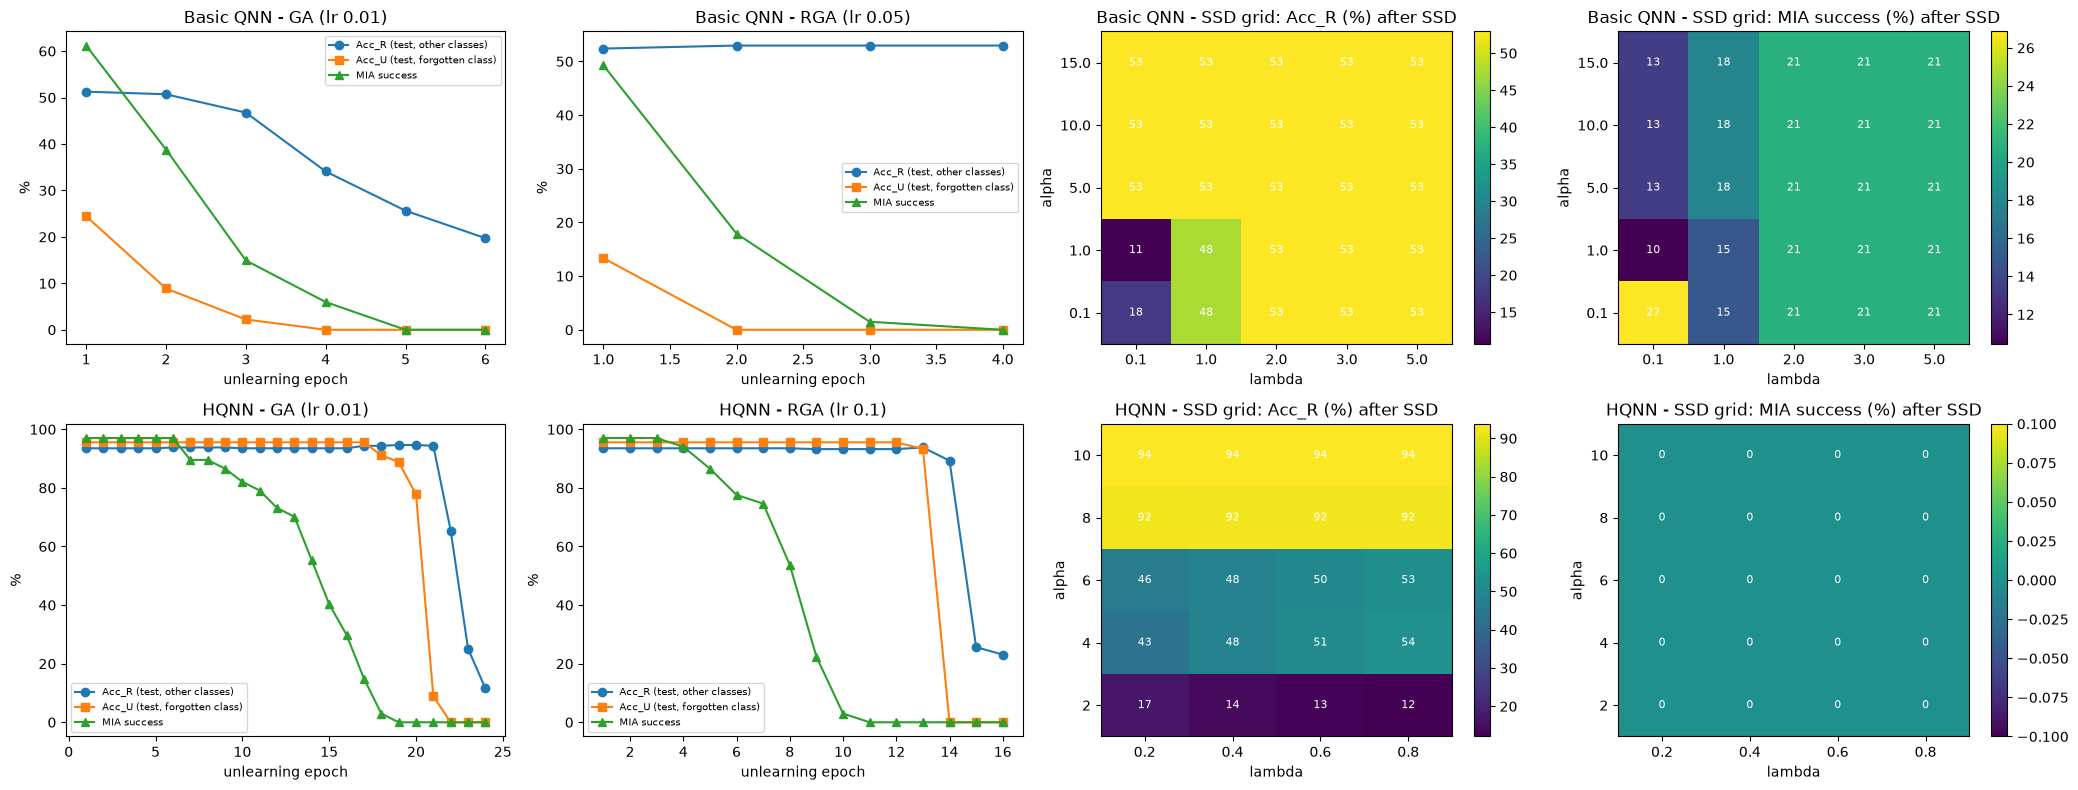

In [24]:
fig, ax = plt.subplots(2, 4, figsize=(21, 8))
for i_, kind in enumerate(("qnn", "hqnn")):
    U = UNL_RES[(0, kind)]
    for j_, meth in enumerate(("GA", "RGA")):
        cv = U["curves"][meth]; a = ax[i_, j_]
        a.plot(cv.epoch, 100 * cv.AccR, "o-", label="Acc_R (test, other classes)"); a.plot(cv.epoch, 100 * cv.AccU, "s-", label="Acc_U (test, forgotten class)")
        a.plot(cv.epoch, 100 * cv.MIA, "^-", label="MIA success")
        a.set_title(f"{ARCH_NAME[kind]} - {meth} (lr {UNL[kind]['ga_lr' if meth == 'GA' else 'rga_lr']})"); a.set_xlabel("unlearning epoch"); a.set_ylabel("%"); a.legend(fontsize=7)
    g = U["grid"]
    for j_, (col, ttl) in enumerate([("AccR", "Acc_R (%) after SSD"), ("MIA", "MIA success (%) after SSD")]):
        piv = g.pivot(index="alpha", columns="lam", values=col) * 100
        im = ax[i_, 2 + j_].imshow(piv.values, origin="lower", cmap="viridis", aspect="auto")
        ax[i_, 2 + j_].set_xticks(range(len(piv.columns))); ax[i_, 2 + j_].set_xticklabels(piv.columns); ax[i_, 2 + j_].set_yticks(range(len(piv.index))); ax[i_, 2 + j_].set_yticklabels(piv.index)
        for (yy, xx), v in np.ndenumerate(piv.values):
            ax[i_, 2 + j_].text(xx, yy, f"{v:.0f}", ha="center", va="center", color="w", fontsize=8)
        ax[i_, 2 + j_].set_xlabel("lambda"); ax[i_, 2 + j_].set_ylabel("alpha"); ax[i_, 2 + j_].set_title(f"{ARCH_NAME[kind]} - SSD grid: {ttl}"); plt.colorbar(im, ax=ax[i_, 2 + j_])
plt.tight_layout(); plt.show()

## 8. Does shot noise break unlearning? (paper Sec. IV.B.3, Fig. 6 and 7)

The HQNN `A_o` is trained analytically; then the adversary **and** the unlearning algorithm only get `N`-shot estimates of the circuit. We emulate this exactly in the simulator:
forward values are `N`-shot averages of the Z outcomes, the gradient of every ansatz angle is the **parameter-shift rule** evaluated with `N` shots for each of the 2 x 120 shifted circuits (the paper's explanation of why GA collapses), and the Fisher information of SSD is built from the same noisy per-sample gradients. The gradient that flows back into the classical CNN is taken from the exact circuit Jacobian (CHOICE: it cannot be obtained by parameter shift because the amplitudes are data, not gates). Section 4 of this notebook (the code cell above) already verified that our parameter-shift Jacobian equals autograd (see the next cell).

**Learning rate and number of epochs (CHOICE).** The paper tracks only 4 GA epochs in Fig. 6, but with its learning rate 0.01 our analytic GA needs about 22 epochs before D_u is forgotten (the first lines of the output below show the search). So the cell picks the smallest learning rate of 0.01, 0.03, 0.05, 0.1, 0.3 whose analytic (exact-simulator) GA forgets D_u within 6 epochs and tracks the N-shot runs for two epochs beyond that point. The dashed black curve is the analytic GA with the same settings. Because a larger learning rate makes the forgetting abrupt, read the retain-accuracy panel together with the table of "GA state at the first epoch with Acc_U <= 5 %".

  analytic GA, lr 0.01: forgets D_u after 22 epoch(s)


  analytic GA, lr 0.03: forgets D_u after 10 epoch(s)


  analytic GA, lr 0.05: forgets D_u after 7 epoch(s)


  analytic GA, lr 0.1: forgets D_u after 5 epoch(s)
shot-noise study: GA learning rate 0.1, analytic GA stops after 5 epoch(s), 7 epochs are tracked


parameter-shift Jacobian (exact, no shots) vs autograd: max |diff| = 1.61e-15


run 0: shot-noise unlearning done [622s]


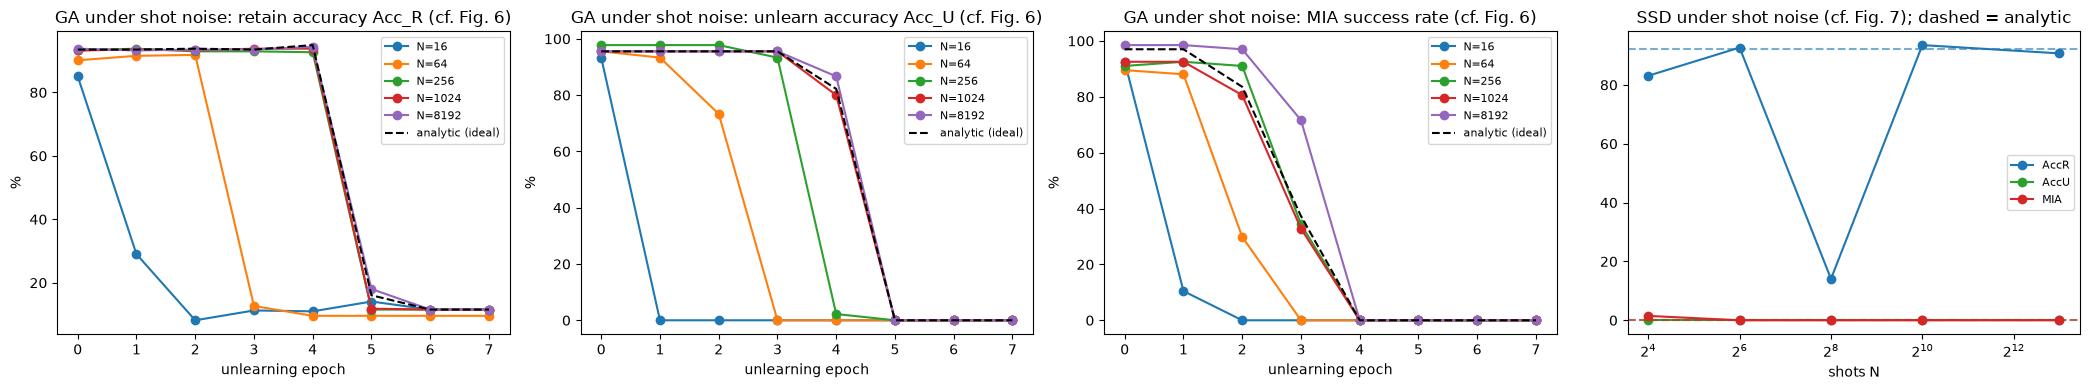

GA, mean over runs (rows: shots, epoch; shots 0 = analytic reference):
             AccR  AccU   MIA
shots epoch                  
0     0      93.5  95.6  97.0
      1      93.5  95.6  97.0
      2      93.8  95.6  83.6
      3      93.5  95.6  37.3
      4      94.9  82.2   0.0
      5      16.1   0.0   0.0
      6      11.5   0.0   0.0
      7      11.5   0.0   0.0
16    0      85.1  93.3  92.5
      1      29.0   0.0  10.4
      2       8.2   0.0   0.0
      3      11.3   0.0   0.0
      4      11.0   0.0   0.0
      5      14.1   0.0   0.0
      6      11.5   0.0   0.0
      7      11.5   0.0   0.0
64    0      90.1  95.6  89.6
      1      91.5  93.3  88.1
      2      91.8  73.3  29.9
      3      12.7   0.0   0.0
      4       9.6   0.0   0.0
      5       9.6   0.0   0.0
      6       9.6   0.0   0.0
      7       9.6   0.0   0.0
256   0      93.2  97.8  91.0
      1      93.8  97.8  92.5
      2      93.0  97.8  91.0
      3      93.0  93.3  34.3
      4      92.7   2.2   0.0

In [25]:
D = DATA[0]; mo = RUNS[(0, "hqnn")]["mo"]
# CHOICE: the paper tracks only 4 GA epochs in Fig. 6, so its GA must forget within a few epochs. With lr 0.01 our GA needs ~20 epochs, so for this
# study we take the smallest learning rate from a short list whose ANALYTIC GA (exact simulator, cheap) forgets D_u within 6 epochs.
SHOT_GA_LR, ga_stop = 0.1, 3
for lr_ in (0.01, 0.03, 0.05, 0.1, 0.3):
    g_ = torch.Generator().manual_seed(D["seed"] + 51)
    m2_, snaps_, _ = gradient_ascent(mo, D, "hqnn", lr_, UNL["hqnn"]["ga_bs"], 30, g_)
    e_ = pick_epoch(m2_, snaps_, D, "hqnn"); m2_.load_state_dict(snaps_[e_])
    hit_ = accuracy(m2_, *split_train(D, "hqnn")[:2]) <= 0.02
    print(f"  analytic GA, lr {lr_}: {'forgets D_u after' if hit_ else 'does not forget within'} {e_ + 1} epoch(s)")
    if hit_ and e_ + 1 <= 6:
        SHOT_GA_LR, ga_stop = lr_, e_ + 1; break
SHOT_UNL_EPOCHS = int(min(max(ga_stop + 2, 4), 10))        # CHOICE: epochs to track = analytic stopping epoch + 2
HP_SHOT = dict(UNL["hqnn"], ga_lr=SHOT_GA_LR)
print(f"shot-noise study: GA learning rate {SHOT_GA_LR}, analytic GA stops after {ga_stop} epoch(s), {SHOT_UNL_EPOCHS} epochs are tracked")
a_ = mo.amp(D["img_tr"][:5]).detach()
W_ = mo.QNN_param.detach().clone().requires_grad_(True)
mm = expvals_from_probs(quantum_probs(a_, W_))
J_ = torch.stack([torch.autograd.grad(mm[:, q].sum(), W_, retain_graph=True)[0].reshape(-1) for q in range(NQ)], 1)
print("parameter-shift Jacobian (exact, no shots) vs autograd: max |diff| = %.2e" % (ps_jacobian(a_, mo.QNN_param.detach()).sum(1) - J_).abs().max().item())
SN = []
t0 = time.time()
for r in range(N_RUNS_SHOTNOISE):
    D = DATA[r]; gen = torch.Generator().manual_seed(D["seed"] + 41)
    U = UNL_RES[(r, "hqnn")]; best = U["df"].set_index("Method").loc["SSD"]
    ga, ssd, ideal, ideal_ssd = shot_noise_unlearning(D, "hqnn", RUNS[(r, "hqnn")]["mo"], HP_SHOT, (float(best["alpha"]), float(best["lam"])), SHOT_GRID_UNLEARN, gen, FISHER_N_SHOT, SHOT_UNL_EPOCHS)
    SN.append(dict(ga=ga.assign(run=r), ssd=ssd.assign(run=r), ideal=ideal, ideal_ssd=ideal_ssd))
    print(f"run {r}: shot-noise unlearning done [{time.time()-t0:.0f}s]")
GA_SN = pd.concat([s["ga"] for s in SN]); SSD_SN = pd.concat([s["ssd"] for s in SN])
GA_SNm = GA_SN.groupby(["shots", "epoch"])[["AccR", "AccU", "MIA"]].mean() * 100
SSD_SNm = SSD_SN.groupby("shots")[["AccR", "AccU", "MIA"]].mean() * 100
fig, ax = plt.subplots(1, 4, figsize=(21, 4))
for j_, (col, ttl) in enumerate([("AccR", "retain accuracy Acc_R"), ("AccU", "unlearn accuracy Acc_U"), ("MIA", "MIA success rate")]):
    for N in SHOT_GRID_UNLEARN:
        s_ = GA_SNm.loc[N]; ax[j_].plot(s_.index, s_[col], "o-", label=f"N={N}")
    s_ = GA_SNm.loc[0]; ax[j_].plot(s_.index, s_[col], "k--", label="analytic (ideal)")
    ax[j_].set_title(f"GA under shot noise: {ttl} (cf. Fig. 6)"); ax[j_].set_xlabel("unlearning epoch"); ax[j_].set_ylabel("%"); ax[j_].legend(fontsize=8)
for col, c_ in [("AccR", "C0"), ("AccU", "C2"), ("MIA", "C3")]:
    ax[3].plot(SSD_SNm.index, SSD_SNm[col], "o-", color=c_, label=col)
    ax[3].axhline(100 * np.mean([s["ideal_ssd"][col] for s in SN]), color=c_, ls="--", alpha=0.6)
ax[3].set_xscale("log", base=2); ax[3].set_xlabel("shots N"); ax[3].set_title("SSD under shot noise (cf. Fig. 7); dashed = analytic"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()
# Retain accuracy at the moment GA has forgotten (first epoch with test Acc_U <= 5 %); NaN = never forgot within the tracked epochs
def at_forgetting(df, thr=5.0):
    hit = df[(df.AccU <= thr) & (df.index >= 1)]
    return (hit.index[0], hit.iloc[0]["AccR"], hit.iloc[0]["MIA"]) if len(hit) else (np.nan, np.nan, np.nan)
STOP_DF = pd.DataFrame({N: at_forgetting(GA_SNm.loc[N]) for N in (0,) + tuple(SHOT_GRID_UNLEARN)}, index=["epoch_forgotten", "AccR", "MIA"]).T
STOP_DF.index.name = "shots (0 = analytic)"
print("GA, mean over runs (rows: shots, epoch; shots 0 = analytic reference):"); print(GA_SNm.round(1).to_string())
print("\nGA state at the first epoch with Acc_U <= 5 % (NaN = did not forget within the tracked epochs):"); print(STOP_DF.round(1).to_string())
print("\nSSD with N-shot Fisher information (mean over runs):"); print(SSD_SNm.round(1).to_string())

## 9. The paper's claims next to the notebook's numbers

Each number of Tables I-II and Figs. 3 and 7 that this setting can test is compared with ours; "reproduced" means within 2 percentage points, "not reached" / "exceeded" means worse / better than the paper by more than that,
and "cannot be checked" is used for the cloud-device rows and wall-clock costs (different machines). Qualitative claims (who leaks more, which method fails where) are tested separately below the table.

In [26]:
# ---------------------------------------------------------------------------------------------
# Paper numbers (Tables I and II, Figs. 3, 6, 7) next to this notebook's numbers, with one verdict per claim.
# Rule: "reproduced" = within 2 percentage points; otherwise "not reached" (worse than the paper) or "exceeded" (better).
# Better = higher for Acc_R and for the original model's leakage-free metrics; lower for Acc_U and MIA after unlearning.
# ---------------------------------------------------------------------------------------------
PAPER_T1 = {("Basic QNN", "loss"): (84.3, 4.9), ("Basic QNN", "logit"): (83.6, 11.7), ("Basic QNN", "softmax"): (75.2, 20.4),
            ("HQNN", "loss"): (98.0, 0.0), ("HQNN", "logit"): (100.0, 4.8), ("HQNN", "softmax"): (100.0, 7.0)}
PAPER_T1_DEVICE = {("Basic QNN", "exp-values"): (67.1, 12.8), ("HQNN", "exp-values"): (83.5, 6.4)}
PAPER_T2 = {   # (Acc_U, Acc_R, MIA, cost in s)
    "Basic QNN": {"A_o": (61.2, 57.1, 95.1, 1785.4), "A_t": (0, 64.2, 0, 1605.2), "GD": (0, 63.7, 22.6, 160.5), "GA": (0, 54.4, 6.8, 10.7),
                  "GA-R": (0, 63.5, 0.0, 107.1), "SSD": (0, 14.8, 5.8, 40.6), "SSD-R": (0, 47.1, 0, 92.6), "RGA": (1.9, 59.8, 2.7, 48.9), "RGA-R": (0, 61.4, 0.0, 82.3)},
    "HQNN": {"A_o": (96.6, 94.0, 100, 357.5), "A_t": (0, 95.8, 0.0, 321.75), "GD": (92.0, 95.1, 100, 321.7), "GA": (0, 89.5, 0.4, 40.0),
             "GA-R": (0, 90.7, 0.0, 74.2), "SSD": (0, 94.2, 0.8, 13.6), "RGA": (0, 93.2, 0.4, 42.1), "RGA-R": (0, 96.5, 0.1, 76.0)}}

def verdict(paper, mine, higher_is_better, tol=2.0):
    gap = mine - paper
    if np.isnan(mine):
        return "cannot be checked", gap
    if abs(gap) <= tol:
        return "reproduced", gap
    better = (gap > 0) == higher_is_better
    return ("exceeded" if better else "not reached"), gap

cmp_rows = []
def add(claim, paper, mine, hib, unit="%", tol=2.0, note=""):
    v, g = verdict(paper, mine, hib, tol)
    cmp_rows.append(dict(claim=claim, paper=paper, notebook=round(float(mine), 1), gap=round(float(g), 1), verdict=v, unit=unit, note=note))

T1m = T1.groupby(["arch", "feature"], sort=False)[["A_o", "A_t"]].mean()
for (arch, feat), (p_o, p_t) in PAPER_T1.items():
    add(f"Table I {arch} {feat}: MIA on original model A_o", p_o, T1m.loc[(arch, feat), "A_o"], True)
    add(f"Table I {arch} {feat}: MIA on target model A_t", p_t, T1m.loc[(arch, feat), "A_t"], False)
for (arch, feat), (p_o, p_t) in PAPER_T1_DEVICE.items():
    for nm, pv, col in (("A_o", p_o, "A_o"), ("A_t", p_t, "A_t")):
        cmp_rows.append(dict(claim=f"Table I {arch} {feat} ({nm}), Tianyan-504 device", paper=pv, notebook=round(float(T1m.loc[(arch, feat), col]), 1),
                             gap=np.nan, verdict="cannot be checked", unit="%", note="paper: real device, ours: noiseless 4096-shot simulation"))
for arch, d in PAPER_T2.items():
    for meth, (pu, pr, pm, pc) in d.items():
        if (arch, meth) not in T2m.index:
            continue
        row = T2m.loc[(arch, meth)]
        add(f"Table II {arch} {meth}: Acc_U", pu, row["AccU"], False)
        add(f"Table II {arch} {meth}: Acc_R", pr, row["AccR"], True)
        add(f"Table II {arch} {meth}: MIA", pm, row["MIA"], False)
        cmp_rows.append(dict(claim=f"Table II {arch} {meth}: cost (s)", paper=pc, notebook=round(float(row["time_s"]), 1), gap=np.nan,
                             verdict="cannot be checked", unit="s", note="paper: different hardware and budgets"))
# Fig. 3 (shot noise at inference, HQNN)
lo, hi = int(min(SHOT_GRID_SWEEP)), int(max(SHOT_GRID_SWEEP))
add(f"Fig. 3 HQNN accuracy at {hi} shots (~ideal)", 96.0, 100 * SWm.loc[hi, ("acc", "mean")], True, note="read off the plot")
add(f"Fig. 3 HQNN MIA at {hi} shots (~ideal)", 94.0, SWm.loc[hi, ("MIA", "mean")], False, note="read off the plot")
add(f"Fig. 3 HQNN accuracy at {lo} shots", 89.0, 100 * SWm.loc[lo, ("acc", "mean")], True, note="read off the plot")
add(f"Fig. 3 HQNN MIA at {lo} shots", 67.0, SWm.loc[lo, ("MIA", "mean")], False, note="read off the plot")
# Fig. 7 (SSD retain accuracy at 16 shots)
add("Fig. 7 SSD retain accuracy at 16 shots", 80.0, SSD_SNm.loc[16, "AccR"], True, note="read off the plot")
CMP = pd.DataFrame(cmp_rows)

# ---- qualitative claims ----
def g1(arch, meth, col):
    return T2m.loc[(arch, meth), col]
qual = []
def q(claim, ok, evidence):
    qual.append(dict(claim=claim, verdict="cannot be checked" if ok is None else ("reproduced" if ok else "not reached here"), evidence=evidence))
leak = T1.groupby("arch")[["A_o", "A_t"]].mean()
q("Both QNNs leak membership: MIA on A_o clearly above MIA on A_t (loss/logit/softmax features, mean)",
  all(leak.loc[a, "A_o"] > leak.loc[a, "A_t"] + 30 for a in ("Basic QNN", "HQNN")), leak.round(1).to_dict("index"))
q("HQNN leaks more than the basic QNN (mean A_o over loss/logit/softmax)", leak.loc["HQNN", "A_o"] > leak.loc["Basic QNN", "A_o"],
  f"HQNN {leak.loc['HQNN','A_o']:.1f} vs basic {leak.loc['Basic QNN','A_o']:.1f}")
q("GD fails to forget on the HQNN (Acc_U and MIA stay high)", g1("HQNN", "GD", "AccU") > 50 and g1("HQNN", "GD", "MIA") > 50,
  f"GD: Acc_U {g1('HQNN','GD','AccU'):.1f}, MIA {g1('HQNN','GD','MIA'):.1f}")
ok = all(g1("HQNN", m, "AccU") < 5 and g1("HQNN", m, "MIA") < 10 for m in ("GA", "SSD", "RGA"))
q("GA, SSD and RGA all drive Acc_U to ~0 and MIA below 10 % on the HQNN", ok,
  {m: (round(g1("HQNN", m, "AccU"), 1), round(g1("HQNN", m, "MIA"), 1)) for m in ("GA", "SSD", "RGA")})
q("SSD is poor on the basic QNN (Acc_R far below that of A_t)", g1("Basic QNN", "SSD", "AccR") < g1("Basic QNN", "A_t", "AccR") - 10,
  f"SSD Acc_R {g1('Basic QNN','SSD','AccR'):.1f} vs A_t {g1('Basic QNN','A_t','AccR'):.1f}")
q("Fine-tuning on D_r (-R) does not hurt and usually restores Acc_R (GA-R >= GA on the HQNN)", g1("HQNN", "GA-R", "AccR") >= g1("HQNN", "GA", "AccR") - 0.5,
  f"GA {g1('HQNN','GA','AccR'):.1f} -> GA-R {g1('HQNN','GA-R','AccR'):.1f}")
q("Retaining accuracy: RGA(-R) keeps Acc_R close to A_t on the HQNN (within 3 points)", g1("HQNN", "RGA-R", "AccR") >= g1("HQNN", "A_t", "AccR") - 3,
  f"RGA-R {g1('HQNN','RGA-R','AccR'):.1f} vs A_t {g1('HQNN','A_t','AccR'):.1f}")
d_mia = SWm.loc[hi, ("MIA", "mean")] - SWm.loc[lo, ("MIA", "mean")]; d_acc = 100 * (SWm.loc[hi, ("acc", "mean")] - SWm.loc[lo, ("acc", "mean")])
q(f"Low shot count ({lo}) at inference lowers MIA more than it lowers accuracy (privacy-utility trade-off, Fig. 3)", d_mia > d_acc,
  f"MIA drop {d_mia:.1f} pts vs accuracy drop {d_acc:.1f} pts")
lowN, highN = min(SHOT_GRID_UNLEARN), max(SHOT_GRID_UNLEARN)
a_ref, a_low, a_high = STOP_DF.loc[0, "AccR"], STOP_DF.loc[lowN, "AccR"], STOP_DF.loc[highN, "AccR"]
q(f"GA is hurt by shot noise: at the epoch where GA has forgotten D_u, Acc_R at {lowN} shots is >10 points below the analytic GA's (Fig. 6)",
  None if np.isnan(a_low) or np.isnan(a_ref) else bool(a_low < a_ref - 10), f"Acc_R at forgetting: {lowN} shots {a_low:.1f}, analytic {a_ref:.1f}")
q(f"GA with {highN} shots follows the analytic trajectory (forgets within 1 epoch of the analytic GA, Acc_R within 10 points)",
  None if np.isnan(STOP_DF.loc[highN, "epoch_forgotten"]) else bool(abs(STOP_DF.loc[highN, "epoch_forgotten"] - STOP_DF.loc[0, "epoch_forgotten"]) <= 1 and abs(a_high - a_ref) <= 10),
  f"epoch forgotten {STOP_DF.loc[highN, 'epoch_forgotten']} vs analytic {STOP_DF.loc[0, 'epoch_forgotten']}; Acc_R {a_high:.1f} vs {a_ref:.1f}")
ideal_ssd_accR = 100 * np.mean([s["ideal_ssd"]["AccR"] for s in SN])
q("SSD is robust to shot noise: Acc_R at 16 shots stays within 15 points of the analytic SSD (Fig. 7)",
  SSD_SNm.loc[16, "AccR"] >= ideal_ssd_accR - 15, f"Acc_R {SSD_SNm.loc[16,'AccR']:.1f} vs analytic {ideal_ssd_accR:.1f}")
t_h = {m: g1("HQNN", m, "time_s") for m in ("GA", "SSD", "RGA")}
q("SSD is the cheapest of the three methods on the HQNN (paper: 13.6 s vs 40.0 s and 42.1 s)", t_h["SSD"] < min(t_h["GA"], t_h["RGA"]),
  {k: round(v, 1) for k, v in t_h.items()})
QUAL = pd.DataFrame(qual)

pd.set_option("display.width", 220, "display.max_colwidth", 110, "display.max_rows", 200)
print("=== Quantitative claims (paper vs this notebook) ===")
print(CMP[["claim", "paper", "notebook", "gap", "verdict", "note"]].to_string(index=False))
print("\nVerdict counts:", CMP.verdict.value_counts().to_dict())
print("\n=== Qualitative claims ===")
print(QUAL.to_string(index=False))
print("\nVerdict counts:", QUAL.verdict.value_counts().to_dict())

=== Quantitative claims (paper vs this notebook) ===
                                                 claim   paper  notebook   gap           verdict                                                     note
     Table I Basic QNN loss: MIA on original model A_o   84.30      82.4  -1.9        reproduced                                                         
       Table I Basic QNN loss: MIA on target model A_t    4.90       0.0  -4.9          exceeded                                                         
    Table I Basic QNN logit: MIA on original model A_o   83.60      30.3 -53.3       not reached                                                         
      Table I Basic QNN logit: MIA on target model A_t   11.70      34.9  23.2       not reached                                                         
  Table I Basic QNN softmax: MIA on original model A_o   75.20      94.0  18.8          exceeded                                                         
    Table I Basic QNN s

## 10. Reading the paper critically

**What this run shows.** On the HQNN the paper's story is reproduced well: the attack separates A_o from A_t (loss 96 % versus 0 %, logits 98.5 % versus 1.6 %), GD does not forget (Acc_U 94 %, MIA 97 %), and GA, SSD and RGA all reach Acc_U = 0 and MIA = 0 with Acc_R of 78 %, 92.6 % and 90.7 % (paper 89.5, 94.2, 93.2). SSD is also poor on the basic QNN, as the paper says (Acc_R 9 % versus the paper's 15 %). Where the notebook falls short the reasons are stated next to the numbers: the basic QNN is only trained to about 48 % test accuracy (the paper's reaches 57 %), the attack is a weak classifier, and we average over 2 runs instead of 20.

**1. "MIA success rate" is a recall, not an accuracy.** The paper's number is the share of the forgotten-class training samples that the attack calls "member". An attacker that answers "member" to everything scores 100 %. The notebook prints `fit_acc`, the balanced accuracy of each attack on its own training data: 53-68 % for the HQNN (train accuracy 100 %, test 93.8 %, so the gap is only about 6 points) and 55-63 % for the basic QNN. That is only a little better than a coin, so a large share of the 90-100 % entries of Table I come from an attacker that is biased towards "member", and the same entries are sometimes 0 % in one run and 100 % in the next (HQNN softmax: 100 % and 0 %, mean 50 +- 71). The paper does not report the attack's accuracy on non-members, which is what would settle the question.

**2. The A_t column is easy by construction.** The retrained model never saw the forgotten digit, so it classifies it badly, its loss is high and any attack answers "non-member". A_t therefore measures "the class is absent", not "membership is hidden". Likewise `Acc_U = 0` is the target by definition of class unlearning, so reaching it is less informative than it looks; instance-level unlearning (exercise 5) is the harder and more relevant test.

**3. Leakage is not quantum-specific.** The classical twin of the HQNN (same CNN, quantum layer replaced by a classical layer) is attacked just as easily with the loss feature (100 % on D_u), and an RBF SVM reaches almost the same test accuracy (92.5 % against 93.8 %) as the HQNN on the same inputs. Nothing in the paper claims a quantum advantage, but nothing in it shows that the quantum layer matters for the leakage either; the HQNN leaks more than the basic QNN because it overfits more (training accuracy 100 % against about 58 %), as it would classically.

**4. The paper's text and code disagree in places.** "10 qubits" (code: 8), "3 x 3 convolutions" (code: 5 x 5 with 5 channels), GA learning rates of 0.01 in one paragraph and 0.003 / 0.001 in another, RGA rates 0.01 / 0.05 versus 0.05 / 0.1, and Eq. (12) for SSD, which as printed would never dampen anything. The released repository contains neither the unlearning code for SSD and RGA nor the attack tables, the training epochs, or the Tianyan-504 scripts, so every such gap is a `# CHOICE` above.

**5. Gradient ascent is a cliff, not a slope.** The loss of a well-fitted sample has almost no gradient, so GA does nothing for about 20 epochs at the paper's learning rate 0.01, then forgets suddenly, and a few epochs later the whole model is destroyed (Acc_R falls to about 10 %). All GA numbers therefore depend on the stopping rule (ours: first epoch with at most 2 % training accuracy on D_u), which the paper describes only as "a preset threshold". The run-to-run spread is large (HQNN GA Acc_R 78 +- 18 %). Fine-tuning on D_r afterwards (the "-R" variants) restores Acc_R but can also re-teach the forgotten digit through generalisation: RGA-R has Acc_U = 18.9 +- 26.7 % here (in one of the two runs the fine-tuning brought a large part of the forgotten digit back), whereas the paper reports exactly 0.

**6. Shot noise as a "natural defence" is weaker than advertised.** With one query per sample the attack still reaches 87 % at 16 shots (analytic 97 %) and its own balanced accuracy only falls from 70 to 60 %; the paper's 94 % to 67 % is not reached in this run. Accuracy falls from 93.6 to 84 % (paper 96 to 89 %). The two curves fall by similar amounts in our data, so the claimed asymmetry (privacy drops much more than utility) is at best marginal here. The paper itself notes that repeated queries average the noise away and gives no formal guarantee.

**7. The shot-noise unlearning study (Figs. 6 and 7) is the least comparable part.** The paper tracks 4 GA epochs; with lr 0.01 our analytic GA needs 22, so for this study the learning rate is raised to 0.1 (the smallest of 0.01, 0.03, 0.05, 0.1, 0.3 whose analytic GA forgets within 6 epochs). At that rate even the analytic GA destroys the model at the very epoch it forgets (Acc_R 16 %), so "retain accuracy collapses at low shots" cannot be told apart from "retain accuracy collapses once GA works". What the run does show is that N-shot GA with 8192 shots follows the analytic trajectory (forgets at epoch 5 in both), whereas with 16 shots the noisy gradient makes it forget earlier (epoch 1). SSD with a noisy Fisher estimate keeps Acc_R at 83 % for 16 shots (analytic 92 %), as the paper claims, but one of five shot counts (256) gives 14 %: with a single noisy Fisher estimate per setting SSD is robust on average, not each time. The gradient into the classical CNN is taken from the exact circuit (a `# CHOICE`), which favours both methods.

**8. Costs are not comparable.** The paper's costs come from different hardware and, for the cloud runs, from queue and shot costs. In our exact simulator GA is by far the cheapest method (a few seconds) because its gradients are exact, and SSD pays for two Fisher passes over D_r and D_u; on a device where every gradient needs 2 x 120 circuits per sample, the ranking could be different, but the paper does not count circuit executions.

**9. What cannot be checked.** Table I's device rows and the whole of Table III used the Tianyan-504 superconducting processor (readout error 9.6 %, two-qubit error 8.6 %). Our simulated 4096-shot "exp-values" rows show the same direction (A_o 98.5 % versus A_t 2.4 % for the HQNN) without any noise, which says nothing about what a noisy device would return.

**10. Statistical support.** The paper averages 20 seeds without error bars in the tables; this notebook uses 2 runs (different image draws, forgotten digit and initialisation) with the standard deviation printed, and the shot-noise studies use a single run. Differences of a few percentage points between the paper's and our numbers are therefore within what the seeds alone can produce.

## 11. Exercises

1. **More epochs for the basic QNN.** Set `FAST_MODE = False` and raise `EPOCHS_QNN` to 200 (the authors' budget). Does the basic QNN's Table I leakage move towards the paper's 84 %? Plot the attack's `fit_acc` against the model's train-test accuracy gap.
2. **Strict attacker.** Table I's third column hides the forgotten class from the attacker. Which features still leak, and what does that tell you about "memorising the class" versus "memorising the members"?
3. **SSD's beta.** Implement Eq. (12) literally (beta = min(lambda F_u / F_r, 1)) and rerun the SSD grid on the HQNN. For which (alpha, lambda) does anything get dampened at all?
4. **Query budget.** The paper restricts the attacker to one query per sample. Let the attacker average k = 1, 4, 16 repeated queries at N = 16 shots and redraw Fig. 3. How many repeats undo the "natural defence" of shot noise?
5. **Instance unlearning.** Replace the class-level D_u by 20 randomly chosen training images of different digits. Which of GA, SSD and RGA still works, and what is the right `Acc_U` metric when the forgotten samples are no longer a whole class?